# 01 — Brain MRI Dataset Exploration (EDA)

## Project: BrainScan AI

### Objective

The objective of this notebook is to explore and understand the brain MRI dataset before performing preprocessing or training any Deep Learning models.

Our project consists of two independent tasks:

1. **Image Classification:** Using GoogLeNet (InceptionV1) to classify brain MRI images into four categories.
2. **Object Detection:** Using YOLOv8 to detect and localize brain tumors through bounding boxes.

### Dataset

**Source:** Kaggle — MRI for Brain Tumor with Bounding Boxes

**Classes:**
- Glioma
- Meningioma
- No Tumor
- Pituitary

### Exploration Workflow

1. Locate and inspect the dataset.
2. Examine the directory structure.
3. Count images and annotation files.
4. Inspect YOLO annotation formats.
5. Verify image integrity.
6. Validate bounding-box annotations.
7. Visualize images and their annotations.
8. Analyze class distributions.
9. Check for duplicates and data leakage.
10. Prepare a reliable train/validation/test splitting strategy.

### Expected Outcome

By the end of this notebook, we should understand the dataset's structure, identify quality issues, and determine how to prepare it for both classification and detection.

## 1.1 — Dataset Location and Path Configuration

### Objective

Locate the original dataset and verify that it can be accessed successfully.

### Why is this important?

Before performing any data analysis, we must ensure that our dataset exists at the expected location.

Incorrect file paths can cause data-loading errors and make the project difficult to reproduce on another machine.

### Approach

We use Python's `pathlib` library to manage filesystem paths.

- `Path.cwd()` retrieves the current working directory.
- `.resolve()` converts a path into its absolute representation.
- `.parent` accesses the parent directory.
- `.exists()` verifies that a file or directory exists.

Using `pathlib` makes our code more portable and easier to maintain.

### Dataset Organization

The original dataset is stored in:

`data/raw/brain_mri/`

**Important:** The raw dataset must remain unchanged. All future preprocessing operations will produce separate files inside `data/processed/`.

In [2]:
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "brain_mri"

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())

Project root: /home/houssam/Desktop/Briefs/Brief 5
Dataset root: /home/houssam/Desktop/Briefs/Brief 5/data/raw/brain_mri
Dataset exists: True


### Result

The project root and dataset directory were identified successfully.

**Dataset exists:** `True`

This confirms that the original MRI dataset is accessible and ready for exploration.

## 1.2 — Dataset Directory Structure

### Objective

Examine the organization of the dataset to understand how images, annotations, and class labels are stored.

### Why is this important?

Our two Deep Learning models require different input formats:

- **GoogLeNet:** Images associated with their classification labels.
- **YOLOv8:** Images associated with bounding-box annotations.

Understanding the original directory structure helps us design the appropriate preprocessing pipelines without modifying the source data.

### Approach

We inspect the dataset folders using `pathlib`.

- `iterdir()` retrieves the immediate contents of a directory.
- `is_dir()` checks whether a path represents a directory.

We examine both the training and validation partitions.

In [3]:
for split in ["Train", "Val"]:
    split_path = DATA_ROOT / split

    print(f"\n{split}/")

    if not split_path.exists():
        print("  Directory not found")
        continue

    for folder in sorted(split_path.iterdir()):
        if folder.is_dir():
            print(f"  {folder.name}/")

            for subfolder in sorted(folder.iterdir()):
                if subfolder.is_dir():
                    print(f"    {subfolder.name}/")


Train/
  Glioma/
    images/
    labels/
  Meningioma/
    images/
    labels/
  No Tumor/
    images/
    labels/
  Pituitary/
    images/
    labels/

Val/
  Glioma/
    images/
    labels/
  Meningioma/
    images/
    labels/
  No Tumor/
    images/
    labels/
  Pituitary/
    images/
    labels/


### Findings

The dataset contains two predefined partitions:

- `Train`
- `Val`

Each partition contains four class directories:

1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

Each class directory contains two subdirectories:

- `images/`: MRI image files.
- `labels/`: Corresponding annotation files in YOLO format.

### Interpretation

The dataset is organized by both class and data partition.

This structure provides the information needed for our two tasks:

**Classification:** The class directory can serve as the image-level label, subject to validation.

**Detection:** The annotation files provide bounding-box information that YOLOv8 can use during training.

We will later transform the dataset into two model-specific structures while preserving the original files.

## 1.3 — Image and Annotation Distribution

### Objective

Count the number of images and annotation files in each class and dataset partition.

### Why is this important?

Counting files allows us to:

1. Understand the total dataset size.
2. Identify potential class imbalance.
3. Compare the training and validation distributions.
4. Detect differences between the number of images and annotation files.

Class imbalance is particularly important because models trained on imbalanced datasets may favor frequently represented classes.

### Approach

We recursively inspect each class directory using `rglob()`.

We distinguish files by their extensions:

- Images: `.jpg`, `.jpeg`, `.png`, `.bmp`
- Annotations: `.txt`

The results are collected into a pandas DataFrame for easier analysis.

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for split in ["Train", "Val"]:
    split_path = DATA_ROOT / split

    if not split_path.exists():
        continue

    for class_dir in sorted(split_path.iterdir()):
        if not class_dir.is_dir():
            continue

        files = [
            file for file in class_dir.rglob("*")
            if file.is_file()
        ]

        image_count = sum(
            file.suffix.lower() in IMAGE_EXTENSIONS
            for file in files
        )

        label_count = sum(
            file.suffix.lower() == ".txt"
            for file in files
        )

        records.append({
            "split": split,
            "class_folder": class_dir.name,
            "images": image_count,
            "labels": label_count,
        })

df_summary = pd.DataFrame(records)

display(df_summary)

print("\nTotal images:", df_summary["images"].sum())
print("Total label files:", df_summary["labels"].sum())

,split,class_folder,images,labels
0,Train,Glioma,1153,1153
1,Train,Meningioma,1449,1449
2,Train,No Tumor,711,711
3,Train,Pituitary,1424,1424
4,Val,Glioma,136,136
5,Val,Meningioma,140,140
6,Val,No Tumor,100,100
7,Val,Pituitary,136,136



Total images: 5249
Total label files: 5249


### Results

| Class | Training Images | Validation Images | Total |
|---|---:|---:|---:|
| Glioma | 1,153 | 136 | 1,289 |
| Meningioma | 1,449 | 140 | 1,589 |
| No Tumor | 711 | 100 | 811 |
| Pituitary | 1,424 | 136 | 1,560 |
| **Total** | **4,737** | **512** | **5,249** |

### Key Findings

**1. Dataset size**

The dataset contains 5,249 images and 5,249 annotation files.

The number of image files equals the number of annotation files globally and in every class directory.

However, this does not yet prove that every image has a correctly matched or valid annotation.

**2. Class imbalance**

The dataset is not perfectly balanced.

- Meningioma: 1,589 images
- Pituitary: 1,560 images
- Glioma: 1,289 images
- No Tumor: 811 images

The `No Tumor` category is the least represented class, whereas Meningioma is the most represented.

This imbalance may influence classification performance and should be considered when designing the training strategy.

**3. Existing dataset split**

The dataset currently contains approximately:

- Training: 90.25%
- Validation: 9.75%

There is no dedicated test partition in the inspected directory structure.

### Important Decision

The project requires a 70% training, 15% validation, and 15% test split.

We will establish this split after checking duplicates, patient identifiers, and possible data leakage.

The same split assignments should be reused in both the classification and detection pipelines.

We will not modify the original partitions until the data audit is complete.

## 1.4 — YOLO Annotation Format Inspection

### Objective

Inspect the annotation files to understand how tumor locations and class identifiers are represented.

### YOLO Annotation Format

Each annotated object is generally represented by five values:

`class_id x_center y_center width height`

Where:

- `class_id`: Integer identifying the object's category.
- `x_center`: Horizontal center of the bounding box.
- `y_center`: Vertical center of the bounding box.
- `width`: Width of the bounding box.
- `height`: Height of the bounding box.

The four bounding-box coordinates are normalized relative to the image dimensions.

### Why is this important?

YOLOv8 requires correctly formatted annotations for object detection.

Incorrect coordinates, invalid class identifiers, or mismatched image-label files can negatively affect training and evaluation.

### Approach

We locate annotation files using `rglob("*.txt")` and inspect an example using `read_text()`.

At this stage, we are inspecting the format only. Full annotation validation will be performed in a later section.

In [5]:
label_files = sorted(DATA_ROOT.rglob("*.txt"))

print("TXT files found:", len(label_files))

if label_files:
    sample_label = label_files[0]

    print("\nSample file:")
    print(sample_label.relative_to(DATA_ROOT))

    print("\nContents:")
    print(sample_label.read_text()[:1000])

TXT files found: 5249

Sample file:
Train/Glioma/labels/Te-glTr_0000.txt

Contents:
0 0.555664 0.653320 0.146484 0.193359



### Results

A total of **5,249 TXT annotation files** were found.

Example annotation:

`0 0.555664 0.653320 0.146484 0.193359`

### Interpretation

The sampled annotation contains five values:

- Class ID: `0`
- X center: `0.555664`
- Y center: `0.653320`
- Width: `0.146484`
- Height: `0.193359`

All four bounding-box coordinates are within the normalized range [0, 1].

The bounding box occupies approximately:

- 14.65% of the image width.
- 19.34% of the image height.

The sampled line follows the expected five-field YOLO annotation structure.

### Important Observations

A single valid-looking annotation does not guarantee that the entire dataset is correct.

We still need to verify:

1. Whether every image has a matching annotation.
2. Whether class identifiers are consistent across folders.
3. Whether bounding boxes remain inside image boundaries.
4. Whether annotations contain invalid or empty entries.
5. Whether `No Tumor` annotations represent actual objects or background regions.

### Next Step

Perform systematic image-integrity checks and annotation validation before preparing the datasets for training.

## 1.5 — Image Integrity and Properties Verification

### Objective

Verify that all MRI images are readable and identify their main properties before preprocessing.

### Why is this important?

Deep Learning models require valid image inputs with consistent shapes and compatible color channels.

Before training, we need to detect:
- Corrupted or unreadable image files.
- Different image dimensions.
- Different color modes (Grayscale, RGB, RGBA).
- Unexpected image formats.

### Approach

We use the Python Pillow (PIL) library to open and inspect every image.

For each image, we will:

1. Verify the image file structure.
2. Decode the image to detect reading errors.
3. Extract its width and height.
4. Identify its color mode and format.
5. Record any errors without stopping the entire inspection.

The original images will remain unchanged.

In [6]:
from PIL import Image, UnidentifiedImageError
import pandas as pd

image_records = []
invalid_images = []

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["Train", "Val"]:
    for class_dir in sorted((DATA_ROOT / split).iterdir()):

        if not class_dir.is_dir():
            continue

        images_dir = class_dir / "images"

        if not images_dir.is_dir():
            continue

        for image_path in sorted(images_dir.rglob("*")):

            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            try:
                # Step 1: Verify file integrity
                with Image.open(image_path) as img:
                    img.verify()

                # Step 2: Reopen and decode the image
                with Image.open(image_path) as img:
                    img.load()

                    width, height = img.size
                    mode = img.mode
                    image_format = img.format

                # Step 3: Record image properties
                image_records.append({
                    "split": split,
                    "class": class_dir.name,
                    "filename": image_path.name,
                    "path": str(image_path),
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "format": image_format,
                })

            except Exception as e:
                invalid_images.append({
                    "path": str(image_path),
                    "error": str(e),
                })

df_images = pd.DataFrame(image_records)
df_invalid = pd.DataFrame(invalid_images)

print("Valid images:", len(df_images))
print("Invalid images:", len(df_invalid))

if not df_invalid.empty:
    display(df_invalid)

display(df_images.head())

Valid images: 5249
Invalid images: 0


,split,class,filename,path,width,height,mode,format
0,Train,Glioma,Te-glTr_0000.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,512,512,RGB,JPEG
1,Train,Glioma,Te-glTr_0005.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,512,512,RGB,JPEG
2,Train,Glioma,Te-glTr_0007.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,512,512,RGB,JPEG
3,Train,Glioma,Te-gl_0014.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,512,512,RGB,JPEG
4,Train,Glioma,Te-gl_0015.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,512,512,RGB,JPEG


In [7]:
print("Image dimensions summary:")
display(df_images[["width", "height"]].describe())

print("\nMost common image dimensions:")

dimension_counts = (
    df_images
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)

display(dimension_counts.head(10))

Image dimensions summary:


,width,height
count,5249.000000,5249.000000
mean,481.947609,484.467518
std,106.057852,100.134268
min,150.000000,168.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,1375.000000,1446.000000



Most common image dimensions:


,width,height,count
0,512,512,4206
1,225,225,119
2,630,630,66
3,442,442,42
4,236,236,33
5,256,256,25
6,201,251,23
7,201,250,22
8,214,236,18
9,468,444,15


In [8]:
print("Image color modes:")

display(
    df_images["mode"]
    .value_counts()
    .rename_axis("mode")
    .reset_index(name="count")
)

print("\nColor modes by class:")

display(
    pd.crosstab(
        df_images["class"],
        df_images["mode"]
    )
)

print("\nImage formats:")

display(df_images["format"].value_counts())

Image color modes:


,mode,count
0,RGB,4247
1,L,998
2,RGBA,3
3,P,1



Color modes by class:


mode,L,P,RGB,RGBA
class,,,,
Glioma,470,0,819,0
Meningioma,292,0,1297,0
No Tumor,15,1,792,3
Pituitary,221,0,1339,0



Image formats:


format
JPEG    5245
PNG        4
Name: count, dtype: int64


### 1.5 — Findings and Interpretation

#### 1. Image Integrity

The image integrity verification produced the following results:

- **Total images inspected:** 5,249
- **Valid images:** 5,249
- **Invalid images:** 0
- **Integrity verification success rate:** 100%

All images were successfully opened, verified, and decoded using Pillow.

**Interpretation:**

No corrupted or unreadable images were detected by our verification procedure.

Therefore, no images need to be excluded due to file integrity errors at this stage.

---

#### 2. Image Dimensions

The dataset contains images with varying spatial dimensions.

**Statistical Summary:**

| Statistic | Width | Height |
|---|---:|---:|
| Minimum | 150 | 168 |
| Maximum | 1375 | 1446 |
| Mean | 481.95 | 484.47 |
| Median | 512 | 512 |
| Standard deviation | 106.06 | 100.13 |

**Most Common Dimensions:**

| Dimensions | Image Count |
|---|---:|
| 512 × 512 | 4,206 |
| 225 × 225 | 119 |
| 630 × 630 | 66 |
| 442 × 442 | 42 |
| 236 × 236 | 33 |
| 256 × 256 | 25 |

Approximately **80.13% of images have dimensions of 512 × 512 pixels**.

**Interpretation:**

Although most images share the same resolution, the dataset contains images with different sizes and aspect ratios.

Deep Learning models typically require consistent input shapes within training batches.

Therefore, image resizing will be necessary during preprocessing.

For classification, images will be resized according to the input requirements of the selected GoogLeNet implementation.

For object detection, YOLOv8 can use aspect-ratio-preserving resizing with padding (letterboxing) to reduce geometric distortion.

The original images will remain unchanged.

---

#### 3. Image Color Modes

The dataset contains four different color modes.

| Color Mode | Image Count | Percentage |
|---|---:|---:|
| RGB | 4,247 | 80.91% |
| L (Grayscale) | 998 | 19.01% |
| RGBA | 3 | 0.06% |
| P (Palette) | 1 | 0.02% |
| **Total** | **5,249** | **100%** |

**Color Modes by Class:**

| Class | Grayscale | RGB | RGBA | P |
|---|---:|---:|---:|---:|
| Glioma | 470 | 819 | 0 | 0 |
| Meningioma | 292 | 1297 | 0 | 0 |
| No Tumor | 15 | 792 | 3 | 1 |
| Pituitary | 221 | 1339 | 0 | 0 |

**Interpretation:**

The dataset contains images represented using different numbers of channels.

- `L`: Single-channel grayscale images.
- `RGB`: Three-channel images.
- `RGBA`: Four-channel images, including transparency.
- `P`: Palette-indexed images.

Most pretrained image classification models expect three-channel RGB inputs.

Therefore, we will standardize the images to RGB during preprocessing.

Grayscale images can be converted to RGB by replicating their intensity information across three channels.

RGBA and palette-indexed images also require appropriate conversion.

**Important Observation:**

The distribution of image modes varies across tumor classes.

For example, Glioma contains 470 grayscale images, while No Tumor contains only 15.

This difference could introduce unwanted correlations between image representation and class labels.

We should ensure the model learns meaningful anatomical features rather than relying on image-format artifacts.

---

#### 4. Image File Formats

The dataset contains:

| Format | Image Count |
|---|---:|
| JPEG | 5,245 |
| PNG | 4 |
| **Total** | **5,249** |

**Interpretation:**

Nearly all images are stored in JPEG format.

Pillow successfully decoded both the JPEG and PNG files.

There is no immediate need to convert the original file formats during EDA.

---

### 5. Overall Conclusion

The image integrity analysis confirms that all 5,249 MRI images are readable.

However, two preprocessing requirements have been identified:

1. **Spatial standardization:** Images must be resized to model-compatible dimensions.
2. **Channel standardization:** Images must be converted to a consistent color representation.

We will implement these transformations in the preprocessing pipelines rather than modifying the original dataset.

The analysis also revealed class-dependent differences in image modes, which should be considered when evaluating possible dataset bias.

### Next Step

Validate the YOLO annotation files by checking:

1. Image-label correspondence.
2. Annotation structure and numeric values.
3. Valid class identifiers.
4. Bounding-box coordinate boundaries.
5. Empty or malformed annotations.
6. The meaning of annotations in the No Tumor category.


## 1.6 — YOLO Annotation Validation

### Objective

Validate the annotation files associated with the MRI images before preparing the dataset for YOLOv8 training.

### Validation Strategy

We will perform the following checks:

1. Verify that each image has a matching annotation file.
2. Identify orphan annotation files without corresponding images.
3. Detect ambiguous or duplicate filenames.
4. Validate the structure of YOLO annotation lines.
5. Check class identifiers and normalized bounding-box coordinates.
6. Analyze the annotation distribution across classes.

### Why Is This Important?

Invalid bounding boxes and incorrect class mappings can reduce object detection performance and lead to misleading evaluation results.

Special attention must be given to the `No Tumor` category, because negative images should not contain bounding boxes that are incorrectly interpreted as tumors.

The original dataset will remain unchanged throughout this analysis.

In [9]:
from collections import defaultdict
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

pair_records = []
pair_issues = []
pair_summary = []

for split in ["Train", "Val"]:
    split_dir = DATA_ROOT / split

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        images_dir = class_dir / "images"
        labels_dir = class_dir / "labels"

        images = defaultdict(list)
        labels = defaultdict(list)

        for path in images_dir.iterdir():
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                images[path.stem].append(path)

        for path in labels_dir.iterdir():
            if path.is_file() and path.suffix.lower() == ".txt":
                labels[path.stem].append(path)

        missing = set(images) - set(labels)
        orphan = set(labels) - set(images)

        shared = set(images) & set(labels)

        ambiguous = {
            stem for stem in shared
            if len(images[stem]) != 1 or len(labels[stem]) != 1
        }

        matched = shared - ambiguous

        for stem in sorted(matched):
            pair_records.append({
                "split": split,
                "class_folder": class_dir.name,
                "image_path": images[stem][0],
                "label_path": labels[stem][0],
            })

        for issue_type, stems in [
            ("missing_label", missing),
            ("orphan_label", orphan),
            ("ambiguous_stem", ambiguous),
        ]:
            for stem in sorted(stems):
                pair_issues.append({
                    "split": split,
                    "class_folder": class_dir.name,
                    "issue": issue_type,
                    "stem": stem,
                })

        pair_summary.append({
            "split": split,
            "class": class_dir.name,
            "matched_pairs": len(matched),
            "missing_labels": len(missing),
            "orphan_labels": len(orphan),
            "ambiguous_stems": len(ambiguous),
        })

df_pairs = pd.DataFrame(pair_summary)
df_pair_issues = pd.DataFrame(pair_issues)

display(df_pairs)

print("Total uniquely matched pairs:", len(pair_records))
print("Pairing issues:", len(df_pair_issues))

if not df_pair_issues.empty:
    display(df_pair_issues.head(20))

,split,class,matched_pairs,missing_labels,orphan_labels,ambiguous_stems
0,Train,Glioma,1153,0,0,0
1,Train,Meningioma,1449,0,0,0
2,Train,No Tumor,711,0,0,0
3,Train,Pituitary,1424,0,0,0
4,Val,Glioma,136,0,0,0
5,Val,Meningioma,140,0,0,0
6,Val,No Tumor,98,2,2,0
7,Val,Pituitary,136,0,0,0


Total uniquely matched pairs: 5247
Pairing issues: 4


,split,class_folder,issue,stem
0,Val,No Tumor,missing_label,image(55)
1,Val,No Tumor,missing_label,image(61)
2,Val,No Tumor,orphan_label,image(53)
3,Val,No Tumor,orphan_label,image(60)


### 1.6.3 — Annotation Structure and Coordinate Validation

#### Objective

Verify that every YOLO annotation follows the required format and contains valid numerical values.

#### Validation Rules

Each annotation line must contain exactly five values:

`class_id x_center y_center width height`

The class identifier must be a non-negative integer.

Bounding-box coordinates must be finite numerical values normalized between 0 and 1.

Additionally:
- Width and height must be greater than zero.
- Bounding-box corners must remain inside the image boundaries.
- Empty annotations must be identified separately.
- Class identifier distributions must be examined to determine whether they are consistent across folders.

A small numerical tolerance will be used when checking box boundaries to account for coordinate rounding.

In [10]:
import math

annotation_records = []
annotation_issues = []
empty_labels = []

TOLERANCE = 1e-5

for pair in pair_records:
    label_path = pair["label_path"]

    info = {
        "split": pair["split"],
        "class_folder": pair["class_folder"],
        "label": label_path.name,
    }

    try:
        lines = label_path.read_text(
            encoding="utf-8-sig"
        ).splitlines()

    except Exception as e:
        annotation_issues.append({
            **info,
            "line": None,
            "issue": f"Read error: {e}",
        })
        continue

    if not any(line.strip() for line in lines):
        empty_labels.append(info)
        continue

    for line_number, line in enumerate(lines, start=1):

        if not line.strip():
            continue

        values = line.split()

        if len(values) != 5:
            annotation_issues.append({
                **info,
                "line": line_number,
                "issue": "Expected exactly 5 values",
            })
            continue

        try:
            class_id = int(values[0])

            x, y, w, h = map(float, values[1:])

        except ValueError:
            annotation_issues.append({
                **info,
                "line": line_number,
                "issue": "Invalid numeric values",
            })
            continue

        problems = []

        if class_id < 0:
            problems.append("Negative class ID")

        if not all(math.isfinite(v) for v in [x, y, w, h]):
            problems.append("Non-finite coordinates")

        else:
            if not all(0 <= v <= 1 for v in [x, y, w, h]):
                problems.append("Coordinates outside [0, 1]")

            if w <= 0 or h <= 0:
                problems.append("Non-positive box dimensions")

            x_min = x - w / 2
            x_max = x + w / 2
            y_min = y - h / 2
            y_max = y + h / 2

            if (
                x_min < -TOLERANCE
                or y_min < -TOLERANCE
                or x_max > 1 + TOLERANCE
                or y_max > 1 + TOLERANCE
            ):
                problems.append("Bounding box outside image")

        for problem in problems:
            annotation_issues.append({
                **info,
                "line": line_number,
                "issue": problem,
            })

        annotation_records.append({
            **info,
            "class_id": class_id,
            "x_center": x,
            "y_center": y,
            "width": w,
            "height": h,
            "valid": len(problems) == 0,
        })

df_annotations = pd.DataFrame(annotation_records)
df_annotation_issues = pd.DataFrame(annotation_issues)
df_empty_labels = pd.DataFrame(empty_labels)

print("Parsed annotation rows:", len(df_annotations))
print("Valid annotation rows:", df_annotations["valid"].sum() if not df_annotations.empty else 0)
print("Annotation issues:", len(df_annotation_issues))
print("Empty label files:", len(df_empty_labels))

if not df_annotation_issues.empty:
    display(df_annotation_issues.head(20))

display(df_annotations.head())

Parsed annotation rows: 5871
Valid annotation rows: 5871
Annotation issues: 0
Empty label files: 1


,split,class_folder,label,class_id,x_center,y_center,width,height,valid
0,Train,Glioma,Te-glTr_0000.txt,0,0.555664,0.653320,0.146484,0.193359,True
1,Train,Glioma,Te-glTr_0005.txt,0,0.587891,0.320312,0.144531,0.144531,True
2,Train,Glioma,Te-glTr_0007.txt,0,0.499023,0.573242,0.099609,0.107422,True
3,Train,Glioma,Te-gl_0014.txt,0,0.387695,0.458008,0.150391,0.150391,True
4,Train,Glioma,Te-gl_0015.txt,0,0.687500,0.489258,0.171875,0.275391,True


In [11]:
print("Class IDs found:")
print(sorted(df_annotations["class_id"].unique()))

print("\nClass IDs by image folder:")

class_distribution = pd.crosstab(
    df_annotations["class_folder"],
    df_annotations["class_id"]
)

display(class_distribution)

print("\nEmpty annotation files by class:")

if not df_empty_labels.empty:
    display(
        df_empty_labels["class_folder"].value_counts()
    )
else:
    print("No empty annotation files.")

print("\nBounding boxes per annotation file:")

boxes_per_image = (
    df_annotations
    .groupby(["split", "class_folder", "label"])
    .size()
)

display(
    boxes_per_image
    .value_counts()
    .sort_index()
    .rename_axis("boxes_per_image")
    .reset_index(name="image_count")
)

print("\nNo Tumor annotations:")

no_tumor = df_annotations[
    df_annotations["class_folder"] == "No Tumor"
]

print("Number of annotated boxes:", len(no_tumor))

if not no_tumor.empty:
    no_tumor = no_tumor.copy()
    no_tumor["relative_area"] = (
        no_tumor["width"] * no_tumor["height"]
    )

    display(
        no_tumor[
            ["class_id", "width", "height", "relative_area"]
        ].describe()
    )

    display(no_tumor.head(10))

Class IDs found:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Class IDs by image folder:


class_id,0,1,2,3
class_folder,,,,
Glioma,1500,3,0,164
Meningioma,2,1620,0,109
No Tumor,0,0,809,0
Pituitary,0,1,0,1663



Empty annotation files by class:


class_folder
Glioma    1
Name: count, dtype: int64


Bounding boxes per annotation file:


,boxes_per_image,image_count
0,1,4697
1,2,487
2,3,50
3,4,10
4,5,2



No Tumor annotations:
Number of annotated boxes: 809


,class_id,width,height,relative_area
count,809.0,809.000000,809.000000,809.000000
mean,2.0,0.764107,0.832597,0.641227
std,0.0,0.124568,0.112844,0.157295
min,2.0,0.343897,0.317797,0.134660
25%,2.0,0.682109,0.779070,0.534810
50%,2.0,0.745495,0.848361,0.620125
75%,2.0,0.860169,0.908903,0.753633
max,2.0,0.996063,0.997984,0.991032


,split,class_folder,label,class_id,x_center,y_center,width,height,valid,relative_area
3085,Train,No Tumor,1.txt,2,0.502857,0.675714,0.851429,0.648571,True,0.552212
3086,Train,No Tumor,3.txt,2,0.512397,0.513051,0.770248,0.973899,True,0.750144
3087,Train,No Tumor,4.txt,2,0.525801,0.507601,0.809609,0.984797,True,0.797301
3088,Train,No Tumor,5.txt,2,0.497738,0.451357,0.737557,0.703620,True,0.518960
3089,Train,No Tumor,6.txt,2,0.499206,0.515079,0.671429,0.893651,True,0.600023
3090,Train,No Tumor,7.txt,2,0.493750,0.514706,0.842500,0.825792,True,0.695730
3091,Train,No Tumor,8.txt,2,0.490909,0.507075,0.700000,0.948113,True,0.663679
3092,Train,No Tumor,Tr-noTr_0000.txt,2,0.504286,0.681429,0.860000,0.637143,True,0.547943
3093,Train,No Tumor,Tr-noTr_0002.txt,2,0.509091,0.514682,0.776860,0.970636,True,0.754048
3094,Train,No Tumor,Tr-noTr_0004.txt,2,0.500000,0.443439,0.746606,0.696833,True,0.520260



### 1.6.5 — Findings and Interpretation

#### 1. Image-Label Correspondence

The dataset contains:

- **Total images:** 5,249
- **Total annotation files:** 5,249
- **Uniquely matched image-label pairs:** 5,247
- **Images with missing annotations:** 2
- **Annotation files without matching images:** 2
- **Ambiguous filename stems:** 0

The four correspondence issues were found exclusively in the validation partition of the `No Tumor` class.

| Issue | Filename Stem |
|---|---|
| Missing annotation | image(55) |
| Missing annotation | image(61) |
| Orphan annotation | image(53) |
| Orphan annotation | image(60) |

**Interpretation:**

Although the total number of images equals the total number of annotation files, this does not guarantee correct correspondence.

The dataset contains two images without matching annotations and two annotation files without matching images.

These cases must be investigated before dataset preparation.

We should not automatically rename annotation files because we have not established which annotations belong to which images.

---

#### 2. Annotation Structure Validation

The validation procedure produced the following results:

| Metric | Result |
|---|---:|
| Parsed annotation rows | 5,871 |
| Structurally valid annotation rows | 5,871 |
| Detected numerical or geometric issues | 0 |
| Empty annotation files | 1 |

All 5,871 parsed bounding-box rows passed the implemented checks.

Specifically:

- Each parsed annotation contained five values.
- Class identifiers were non-negative integers.
- Coordinates were finite numerical values.
- Bounding-box dimensions were positive.
- Bounding boxes remained within the normalized image boundaries.

One matched annotation file in the `Glioma` class was empty.

**Interpretation:**

The annotation format is consistent with the expected YOLO structure.

However, this validation confirms only numerical and geometrical correctness. It does not prove that the boxes identify the correct anatomical structures or tumor types.

The empty Glioma annotation requires further investigation because it belongs to a tumor-positive category.

---

#### 3. Bounding Boxes per Image

The distribution of bounding boxes across non-empty, matched annotation files is:

| Bounding Boxes | Number of Images |
|---|---:|
| 1 | 4,697 |
| 2 | 487 |
| 3 | 50 |
| 4 | 10 |
| 5 | 2 |
| **Total** | **5,246** |

The number of parsed bounding-box rows is 5,871.

**Interpretation:**

Most annotated images contain a single bounding box.

However, some images contain multiple annotated regions.

This is supported by the YOLO annotation format, which allows multiple bounding boxes in the same image.

We must preserve valid multiple-object annotations during detection preprocessing.

---

#### 4. Annotation Class Distribution

The dataset contains four distinct annotation class IDs:

`[0, 1, 2, 3]`

Based on the predominant class ID in each directory, the apparent class mapping is:

| Class ID | Apparent Class |
|---|---|
| 0 | Glioma |
| 1 | Meningioma |
| 2 | No Tumor |
| 3 | Pituitary |

The exact mapping should still be confirmed against dataset documentation and visual inspection.

**Observed annotation distribution:**

| Image Folder | ID 0 | ID 1 | ID 2 | ID 3 |
|---|---:|---:|---:|---:|
| Glioma | 1,500 | 3 | 0 | 164 |
| Meningioma | 2 | 1,620 | 0 | 109 |
| No Tumor | 0 | 0 | 809 | 0 |
| Pituitary | 0 | 1 | 0 | 1,663 |

**Important Finding:**

Some images contain bounding boxes whose class IDs differ from their parent folder's expected class.

In total, **279 annotation rows** have class IDs that differ from the apparent class of their parent folders.

These differences are not necessarily errors. They may represent multiple tumor types, incorrect class assignments, or annotation inconsistencies.

We must inspect the affected images before deciding whether any annotations should be corrected or excluded.

---

#### 5. No Tumor Annotation Analysis

The matched `No Tumor` images contain **809 bounding boxes**, all assigned class ID 2.

The bounding-box area relative to the image area was calculated as:

`relative_area = width × height`

Because the coordinates are normalized, this calculation represents the proportion of the image covered by the bounding box.

**Results:**

| Statistic | Relative Area |
|---|---:|
| Minimum | 13.47% |
| 25th percentile | 53.48% |
| Median | 62.01% |
| Mean | 64.12% |
| 75th percentile | 75.36% |
| Maximum | 99.10% |

**Interpretation:**

The bounding boxes in the `No Tumor` category are unusually large.

On average, they cover approximately 64.12% of the image.

This suggests that they may represent a large anatomical or background region rather than a localized tumor.

However, their actual meaning must be confirmed through visualization.

**Potential Preprocessing Decision:**

For the classification model, `No Tumor` remains a valid image-level category.

For a YOLOv8 model specifically designed to localize tumors, confirmed negative images should not contain positive tumor bounding boxes.

If visual inspection confirms that class ID 2 represents non-tumor regions, we should remove those boxes from the derived detection labels while retaining appropriate `No Tumor` images as negative examples.

We must not modify the original annotation files.

---

### 6. Overall Conclusion

The dataset is structurally suitable for further processing, but several annotation-quality concerns remain:

1. Four image-label correspondence issues.
2. One empty annotation file in the Glioma class.
3. Multiple bounding boxes in some images.
4. Class IDs that differ from their corresponding image folder.
5. Very large bounding boxes in the No Tumor category.

No geometric or numerical annotation errors were detected by our current checks.

However, additional visual and semantic validation is necessary before training.

### Next Step

Visualize MRI images together with their bounding boxes to investigate:

- Whether annotations correctly localize tumors.
- Whether mismatched class IDs represent genuine multiple-class annotations or labeling mistakes.
- Whether No Tumor bounding boxes represent non-tumor regions.
- Whether any problematic images should be excluded or corrected during preprocessing.



## 1.7 — MRI Images and Bounding Box Visualization

### Objective

Visualize MRI images together with their YOLO bounding-box annotations to assess annotation quality.

### Why Is This Important?

An annotation can be geometrically valid but still represent an incorrect object or location.

Visual inspection helps identify:
- Incorrectly positioned bounding boxes.
- Suspicious class identifiers.
- Multiple annotated regions.
- Large non-tumor bounding boxes.
- Potentially mislabeled images.

### Visualization Strategy

We will examine three categories of samples:

1. Representative images from each class.
2. Images containing class IDs different from their parent folder.
3. Images from the No Tumor category.

### Approach

We use Pillow to load images and Matplotlib to display them.

Bounding-box coordinates are converted from normalized YOLO format into pixel coordinates.

The original dataset will not be modified.


In [12]:
import random
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

FOLDER_CLASS_IDS = {
    name: class_id
    for class_id, name in CLASS_NAMES.items()
}


def visualize_pairs(pairs, title, max_images=4):

    if not pairs:
        print("No matching samples found.")
        return

    samples = pairs[:max_images]

    fig, axes = plt.subplots(
        1,
        len(samples),
        figsize=(5 * len(samples), 5),
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, pair in zip(axes, samples):

        image_path = pair["image_path"]
        label_path = pair["label_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        img_width, img_height = image.size

        ax.imshow(image)

        lines = label_path.read_text(
            encoding="utf-8-sig"
        ).splitlines()

        for line in lines:

            if not line.strip():
                continue

            values = line.split()

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            # Convert normalized YOLO coordinates to pixels
            x_min = (x - w / 2) * img_width
            y_min = (y - h / 2) * img_height

            box_width = w * img_width
            box_height = h * img_height

            rect = Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                max(y_min - 5, 0),
                CLASS_NAMES.get(class_id, str(class_id)),
                color="yellow",
                fontsize=10,
                weight="bold",
                bbox=dict(facecolor="black", alpha=0.6),
            )

        ax.set_title(
            f"{pair['class_folder']}\n{image_path.name}",
            fontsize=10,
        )

        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

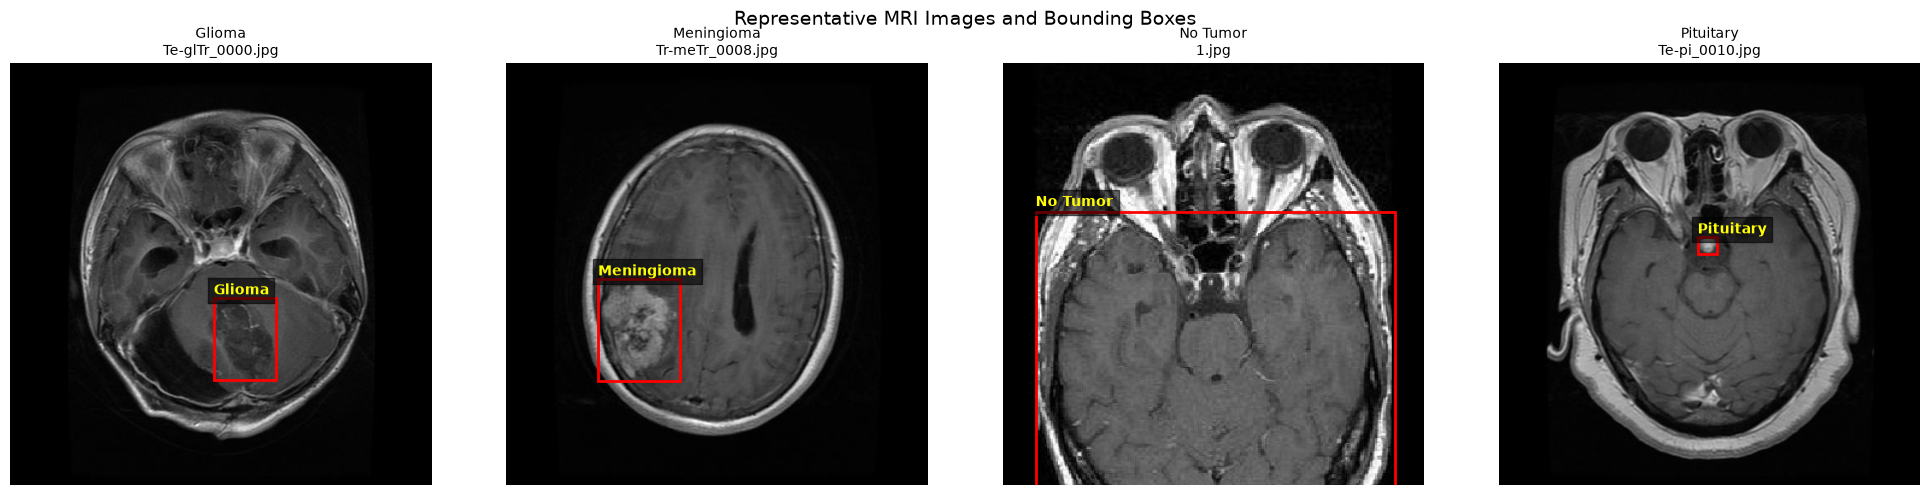

In [13]:
representative_samples = []

for class_name in FOLDER_CLASS_IDS:

    candidates = [
        pair for pair in pair_records
        if pair["class_folder"] == class_name
    ]

    if candidates:
        representative_samples.append(candidates[0])

visualize_pairs(
    representative_samples,
    "Representative MRI Images and Bounding Boxes",
)

Images with unexpected class IDs: 272


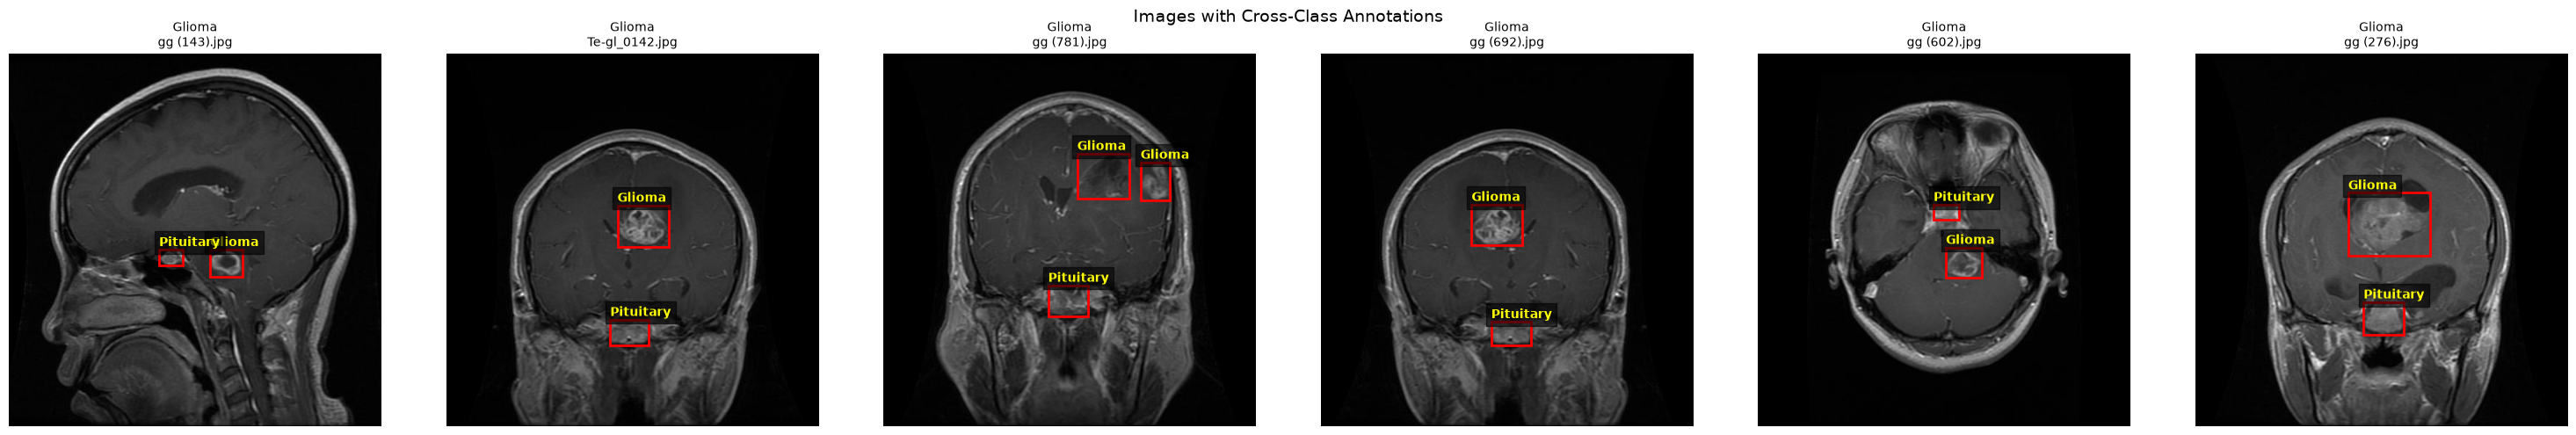

In [14]:
unexpected = df_annotations[
    df_annotations.apply(
        lambda row: row["class_id"]
        != FOLDER_CLASS_IDS[row["class_folder"]],
        axis=1,
    )
]

unexpected_keys = set(
    zip(
        unexpected["split"],
        unexpected["class_folder"],
        unexpected["label"],
    )
)

suspicious_pairs = [
    pair for pair in pair_records
    if (
        pair["split"],
        pair["class_folder"],
        pair["label_path"].name,
    ) in unexpected_keys
]

print("Images with unexpected class IDs:", len(suspicious_pairs))

rng = random.Random(42)

visualize_pairs(
    rng.sample(
        suspicious_pairs,
        min(6, len(suspicious_pairs))
    ),
    "Images with Cross-Class Annotations",
    max_images=6,
)

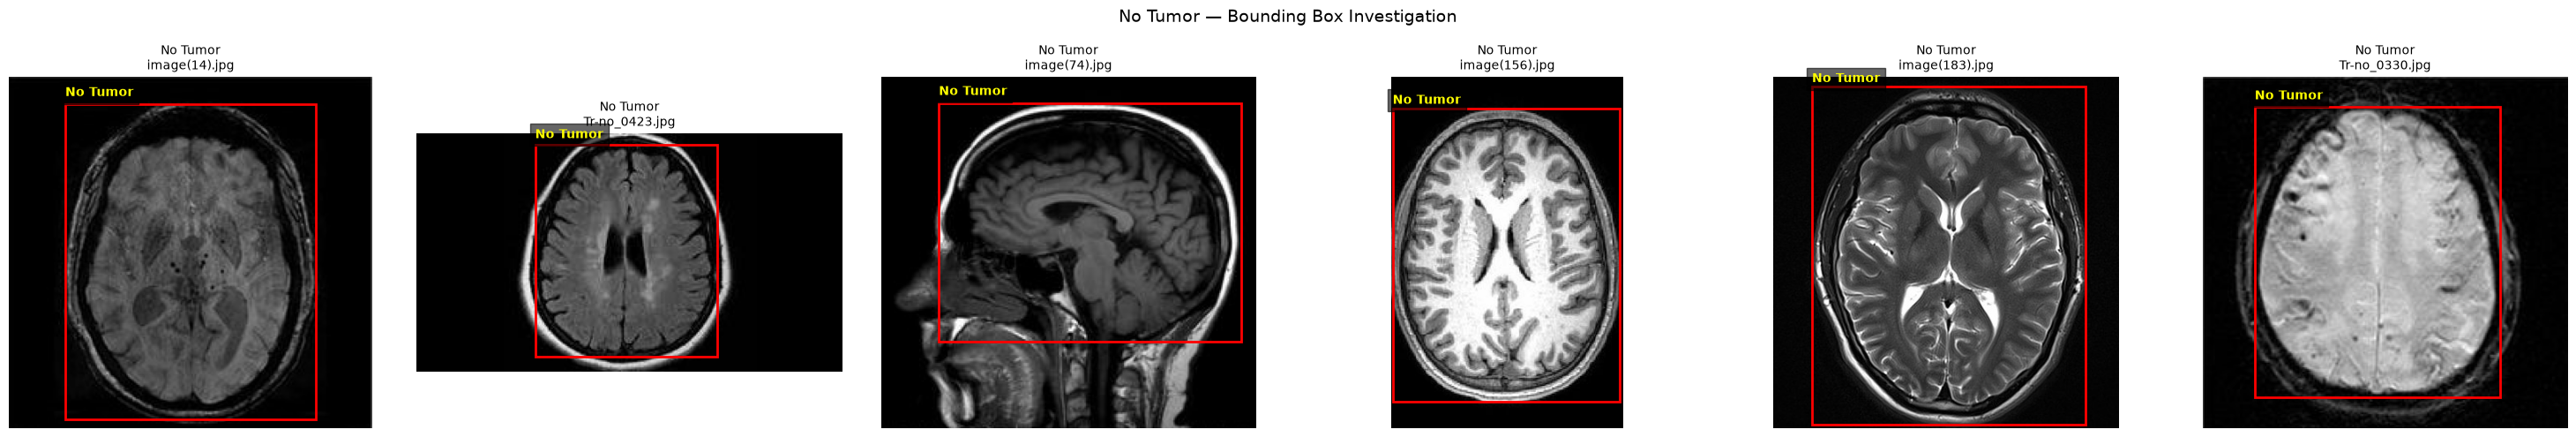

In [15]:
no_tumor_pairs = [
    pair for pair in pair_records
    if pair["class_folder"] == "No Tumor"
]

visualize_pairs(
    rng.sample(
        no_tumor_pairs,
        min(6, len(no_tumor_pairs))
    ),
    "No Tumor — Bounding Box Investigation",
    max_images=6,
)


### 1.7.1 — Findings and Interpretation

#### 1. Representative MRI Images

Four representative images were visualized, corresponding to:

- Glioma
- Meningioma
- No Tumor
- Pituitary

The Glioma, Meningioma, and Pituitary examples contain bounding boxes highlighting localized regions.

The No Tumor example contains a large bounding box covering a substantial portion of the brain.

**Interpretation:**

The visualizations demonstrate that the dataset contains different annotation patterns depending on the image category.

The displayed tumor-positive annotations appear broadly consistent with localized regions, but individual medical correctness has not been independently verified.

---

#### 2. Cross-Class Annotation Investigation

Six images containing cross-class annotations were visualized.

All six sampled images belong to the Glioma directory.

Several contain bounding boxes labeled Pituitary in addition to bounding boxes labeled Glioma.

Some Pituitary boxes appear near the anatomical pituitary region rather than clearly identifying an additional tumor.

**Interpretation:**

These findings raise concerns about the semantic consistency of the annotations.

Possible explanations include:
- Multiple annotated structures in the same image.
- Incorrect class assignments.
- Annotation of normal anatomy as a tumor category.

Further investigation is necessary to distinguish these possibilities.

The 279 cross-class annotation rows identified previously should be considered potentially problematic until reviewed.

No automatic label correction will be performed at this stage.

---

#### 3. No Tumor Bounding Box Investigation

Six images from the No Tumor category were visualized.

The bounding boxes generally cover large portions of the brain rather than localized tumors.

Previous statistical analysis showed:

- Mean relative box area: 64.12%
- Median relative box area: 62.01%
- Maximum relative box area: 99.10%

**Interpretation:**

The visual observations support the hypothesis that these annotations represent large anatomical regions rather than actual tumors.

For a tumor-localization model, these boxes should not be treated as positive tumor detections.

After validating the image-level labels, No Tumor images can instead be retained as negative detection examples with no positive tumor bounding boxes.

The original annotation files will remain unchanged.

---

#### 4. Implications for Model Preparation

**Classification — GoogLeNet**

The classification dataset will retain four image-level classes:

1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

The original class folders provide provisional image-level labels.

**Detection — YOLOv8**

The proposed detection task will focus on three tumor categories:

1. Glioma
2. Meningioma
3. Pituitary

No Tumor images will serve as negative examples after validation.

Suspicious cross-class annotations will require review before inclusion in the training data.

---

### Overall Conclusion

The visual analysis revealed important differences between annotation format validity and annotation meaning.

Although all parsed bounding-box coordinates passed structural validation, some annotations are potentially inconsistent with the objective of tumor localization.

The most significant findings are:

1. No Tumor bounding boxes generally cover large brain regions.
2. Some Glioma images contain additional Pituitary-labeled annotations.
3. The detection dataset will require a specific annotation-cleaning strategy.

### Next Step

Investigate class distributions, duplicate images, and potential train/validation data leakage before establishing the final train/validation/test split.



## 1.8 — Class Distribution and Duplicate Detection

### Objective

Analyze class imbalance and identify duplicate MRI images that could lead to data leakage.

### Why Is This Important?

**Class Imbalance**

If some classes contain significantly more images than others, the model may become biased toward the majority classes.

We need to examine class proportions before deciding whether techniques such as class weighting or augmentation are necessary.

**Duplicate Images**

Duplicate images can negatively affect model evaluation.

If an identical MRI image exists in both the training and validation datasets, the model may be evaluated on information it has already encountered.

This is a form of data leakage.

### Approach

We will:

1. Calculate image counts and percentages by class.
2. Visualize class distributions.
3. Compute SHA-256 hashes to identify byte-identical files.
4. Identify duplicates appearing across different dataset partitions.
5. Investigate duplicates associated with different class labels.

This initial method detects exact file duplicates. Visually similar or re-encoded images will require additional checks.


split,Train,Val,Total,Percentage
class,,,,
Glioma,1153,136,1289,24.56
Meningioma,1449,140,1589,30.27
No Tumor,711,100,811,15.45
Pituitary,1424,136,1560,29.72


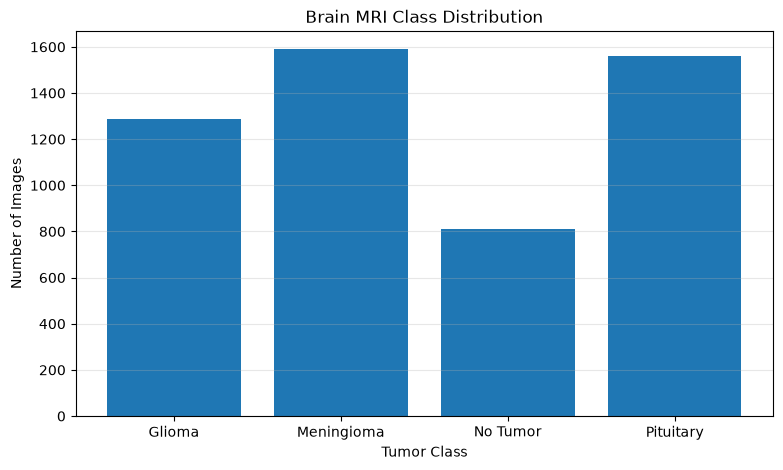

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

class_counts = pd.crosstab(
    df_images["class"],
    df_images["split"]
)

class_counts = class_counts.reindex(
    index=["Glioma", "Meningioma", "No Tumor", "Pituitary"],
    columns=["Train", "Val"],
    fill_value=0
)

class_counts["Total"] = (
    class_counts["Train"] + class_counts["Val"]
)

class_counts["Percentage"] = (
    class_counts["Total"] / class_counts["Total"].sum() * 100
)

display(class_counts.round(2))

# Visualize class distribution
plt.figure(figsize=(9, 5))

plt.bar(
    class_counts.index,
    class_counts["Total"]
)

plt.title("Brain MRI Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [17]:
import hashlib
from pathlib import Path

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


df_hashes = df_images[
    ["split", "class", "filename", "path"]
].copy()

df_hashes["hash"] = df_hashes["path"].apply(
    calculate_sha256
)

# Find files sharing the same hash
duplicates = df_hashes[
    df_hashes.duplicated(
        subset=["hash"],
        keep=False
    )
].sort_values("hash")

duplicate_groups = duplicates["hash"].nunique()

print("Total images:", len(df_hashes))
print("Unique file hashes:", df_hashes["hash"].nunique())
print("Duplicate groups:", duplicate_groups)
print("Images in duplicate groups:", len(duplicates))
print("Redundant copies:", len(duplicates) - duplicate_groups)

display(duplicates.head(20))

Total images: 5249
Unique file hashes: 3913
Duplicate groups: 1228
Images in duplicate groups: 2564
Redundant copies: 1336


,split,class,filename,path,hash
4649,Train,Pituitary,p (757).jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
3335,Train,Pituitary,Te-pi_0049.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
1321,Train,Meningioma,Tr-me_0383.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
2231,Train,Meningioma,m2 (112).jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
4121,Train,Pituitary,p (278).jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,009bb0f6f6174828718de2b4566718aabaf61e819e5676...
3465,Train,Pituitary,Tr-pi_0198.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,009bb0f6f6174828718de2b4566718aabaf61e819e5676...
4090,Train,Pituitary,p (25).jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
5135,Val,Pituitary,Tr-pi_0167.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
4070,Train,Pituitary,p (231).jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,010841515b9457161c3065e47b2b983ebf5883edb809e2...
3431,Train,Pituitary,Tr-pi_0147.jpg,/home/houssam/Desktop/Briefs/Brief 5/data/raw/...,010841515b9457161c3065e47b2b983ebf5883edb809e2...


In [18]:
if duplicates.empty:
    print("No exact duplicate files found.")

else:
    split_counts = (
        duplicates
        .groupby("hash")["split"]
        .nunique()
    )

    cross_split_hashes = split_counts[
        split_counts > 1
    ].index

    cross_split_duplicates = duplicates[
        duplicates["hash"].isin(cross_split_hashes)
    ]

    print(
        "Duplicate groups shared across Train and Val:",
        len(cross_split_hashes)
    )

    display(
        cross_split_duplicates[
            ["split", "class", "filename", "hash"]
        ].head(30)
    )

    class_counts_per_hash = (
        duplicates
        .groupby("hash")["class"]
        .nunique()
    )

    conflicting_hashes = class_counts_per_hash[
        class_counts_per_hash > 1
    ].index

    conflicting_duplicates = duplicates[
        duplicates["hash"].isin(conflicting_hashes)
    ]

    print(
        "\nDuplicate groups with conflicting class folders:",
        len(conflicting_hashes)
    )

    display(
        conflicting_duplicates[
            ["split", "class", "filename", "hash"]
        ].head(30)
    )

Duplicate groups shared across Train and Val: 213


,split,class,filename,hash
4090,Train,Pituitary,p (25).jpg,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
5135,Val,Pituitary,Tr-pi_0167.jpg,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
1335,Train,Meningioma,Tr-me_0400.jpg,010bc80bb8c8dac8251662c1dd9c23d3a210aff06ed540...
4981,Val,Meningioma,m2 (128).jpg,010bc80bb8c8dac8251662c1dd9c23d3a210aff06ed540...
5132,Val,Pituitary,Tr-pi_0140.jpg,034fa02cddc4161d999241e4617fd1d1223249b8aeb76f...
4063,Train,Pituitary,p (225).jpg,034fa02cddc4161d999241e4617fd1d1223249b8aeb76f...
5087,Val,No Tumor,image(266).jpg,039d0eb6b8493db695929536aa7476f8c472381a7c20de...
2663,Train,No Tumor,Tr-no_0253.jpg,039d0eb6b8493db695929536aa7476f8c472381a7c20de...
4157,Train,Pituitary,p (31).jpg,06f85fe1e21a7aeb01b970b8561bc3059fa77daa01cb35...
5143,Val,Pituitary,Tr-pi_0234.jpg,06f85fe1e21a7aeb01b970b8561bc3059fa77daa01cb35...



Duplicate groups with conflicting class folders: 0


,split,class,filename,hash



### 1.8.1 — Findings and Interpretation

#### 1. Class Distribution

The dataset contains 5,249 MRI images distributed across four categories.

| Class | Train | Validation | Total | Percentage |
|---|---:|---:|---:|---:|
| Glioma | 1,153 | 136 | 1,289 | 24.56% |
| Meningioma | 1,449 | 140 | 1,589 | 30.27% |
| No Tumor | 711 | 100 | 811 | 15.45% |
| Pituitary | 1,424 | 136 | 1,560 | 29.72% |
| **Total** | **4,737** | **512** | **5,249** | **100%** |

**Interpretation:**

The dataset is moderately imbalanced.

Meningioma represents the largest class (30.27%), while No Tumor is the smallest (15.45%).

The majority class contains approximately 1.96 times as many images as the minority class.

This imbalance may affect classification performance, particularly the model's ability to correctly identify No Tumor images.

Possible mitigation techniques include:

- Stratified train/validation/test splitting.
- Class weighting during training.
- Training-only data augmentation.
- Per-class evaluation metrics.

The final strategy will be selected after duplicate removal and dataset preparation.

---

#### 2. Exact Duplicate Detection

SHA-256 hashing was used to identify files with identical binary contents.

**Results:**

| Metric | Count |
|---|---:|
| Total images | 5,249 |
| Unique file hashes | 3,913 |
| Duplicate groups | 1,228 |
| Images belonging to duplicate groups | 2,564 |
| Redundant file copies | 1,336 |

**Interpretation:**

The dataset contains a substantial number of exact duplicates.

Approximately 48.85% of image files belong to groups containing at least two identical files.

However, this does not mean that 48.85% of images should be removed.

The actual number of redundant copies is 1,336, representing approximately 25.45% of the dataset.

If one representative image were retained per SHA-256 hash, the dataset would contain 3,913 unique file contents.

Duplicate images may cause some samples to receive excessive influence during training.

They may also produce misleading evaluation results when identical files appear in different data partitions.

---

#### 3. Cross-Split Data Leakage

The duplicate analysis identified:

**213 duplicate groups shared between Train and Val.**

This confirms that the original dataset partitions are not independent at the image-content level.

Some images in the validation partition are byte-identical to images in the training partition, despite having different filenames.

**Interpretation:**

This is direct evidence of data leakage.

A model trained on these partitions may encounter exactly the same image content during both training and validation.

Consequently:

- Validation accuracy may be artificially inflated.
- Validation loss may underestimate generalization error.
- Model selection and hyperparameter tuning may be unreliable.

The original partitions should therefore not be used directly for final model evaluation.

A new splitting strategy is required.

---

#### 4. Duplicate Images with Conflicting Classes

The analysis identified:

**0 duplicate groups containing images assigned to different class folders.**

**Interpretation:**

No byte-identical images were found under conflicting image-level class folders.

This is a positive result for label consistency.

However, it does not guarantee that their YOLO annotations are identical or correct.

Two identical image files might still have different bounding-box coordinates or annotation class IDs.

We must investigate annotation consistency before selecting which duplicate copies to retain.

---

#### 5. Implications for Dataset Preparation

The original dataset contains significant duplication and confirmed cross-split leakage.

We should not train either model directly on the existing Train and Val partitions.

The preparation pipeline should:

1. Identify duplicate groups using file hashes.
2. Check annotation consistency among identical images.
3. Resolve duplicate annotation conflicts.
4. Preserve one canonical image per exact-duplicate group where appropriate.
5. Investigate additional near-duplicates and available patient identifiers.
6. Generate new Train (70%), Validation (15%), and Test (15%) partitions.
7. Ensure that duplicate groups cannot cross dataset boundaries.

The original raw dataset must remain unchanged.

---

### Overall Conclusion

The dataset contains 5,249 readable images, but only 3,913 unique file contents.

The analysis revealed:

- Moderate class imbalance.
- 1,336 redundant image copies.
- 1,228 exact-duplicate groups.
- 213 duplicate groups shared across training and validation.
- No exact-duplicate groups with conflicting image-level class folders.

**Key Finding:**

The existing training and validation partitions contain direct data leakage and must be reconstructed before model development.

### Next Step

Investigate whether identical MRI images contain consistent YOLO annotations, then examine potential near-duplicates before generating leakage-resistant dataset partitions.



## 1.9 — Duplicate Annotation Consistency

### Objective

Determine whether identical MRI images have consistent YOLO bounding-box annotations.

### Why Is This Important?

Exact duplicate images may have different annotation files.

Differences may include:

- Different bounding-box coordinates.
- Different annotation class identifiers.
- Different numbers of bounding boxes.
- Missing or empty annotations.

Removing duplicates without inspecting these differences could result in losing useful annotations or retaining incorrect ones.

### Approach

We will:

1. Group identical images using their SHA-256 hashes.
2. Retrieve the annotation file associated with each image.
3. Normalize annotation values for comparison.
4. Compare annotation contents within each duplicate group.
5. Identify duplicate groups with conflicting annotations.

### Expected Outcome

Identify which duplicate groups have consistent annotations and which require further review before deduplication.


In [19]:
from pathlib import Path
import pandas as pd

# Match image paths to their annotation files
pair_lookup = {
    str(pair["image_path"].resolve()): pair["label_path"]
    for pair in pair_records
}


def annotation_signature(label_path):
    """
    Create a comparable representation of YOLO annotations.
    The order of bounding boxes does not affect comparison.
    """
    if label_path is None:
        return None

    boxes = []

    lines = label_path.read_text(
        encoding="utf-8-sig"
    ).splitlines()

    for line in lines:
        if not line.strip():
            continue

        values = line.split()

        class_id = int(values[0])

        coordinates = tuple(
            round(float(value), 5)
            for value in values[1:]
        )

        boxes.append((class_id, *coordinates))

    return tuple(sorted(boxes))


audit_records = []
detail_records = []

for image_hash, group in df_hashes.rename(
    columns={"class": "class_folder"}
).groupby("hash"):

    if len(group) < 2:
        continue

    signatures = []
    unmatched_count = 0

    for row in group.itertuples(index=False):

        image_path = str(Path(row.path).resolve())
        label_path = pair_lookup.get(image_path)

        signature = annotation_signature(label_path)

        if signature is None:
            unmatched_count += 1
        else:
            signatures.append(signature)

        detail_records.append({
            "hash": image_hash,
            "split": row.split,
            "class": row.class_folder,
            "filename": row.filename,
            "label": label_path.name if label_path else None,
            "annotation_signature": signature,
        })

    unique_signatures = set(signatures)

    audit_records.append({
        "hash": image_hash,
        "image_count": len(group),
        "cross_split": group["split"].nunique() > 1,
        "annotation_versions": len(unique_signatures),
        "annotation_conflict": len(unique_signatures) > 1,
        "unmatched_images": unmatched_count,
    })


df_duplicate_audit = pd.DataFrame(audit_records)
df_duplicate_details = pd.DataFrame(detail_records)

print("Duplicate groups:", len(df_duplicate_audit))

print(
    "Groups with annotation conflicts:",
    df_duplicate_audit["annotation_conflict"].sum()
)

print(
    "Groups containing unmatched images:",
    (df_duplicate_audit["unmatched_images"] > 0).sum()
)

print(
    "Cross-split groups with annotation conflicts:",
    (
        df_duplicate_audit["cross_split"]
        & df_duplicate_audit["annotation_conflict"]
    ).sum()
)

conflicting_hashes = df_duplicate_audit.loc[
    df_duplicate_audit["annotation_conflict"],
    "hash"
]

display(
    df_duplicate_details[
        df_duplicate_details["hash"].isin(conflicting_hashes)
    ].head(30)
)

Duplicate groups: 1228
Groups with annotation conflicts: 1225
Groups containing unmatched images: 0
Cross-split groups with annotation conflicts: 212


,hash,split,class,filename,label,annotation_signature
0,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...,Train,Pituitary,Te-pi_0049.jpg,Te-pi_0049.txt,"((3, 0.49414, 0.48535, 0.08984, 0.06055),)"
1,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...,Train,Pituitary,p (757).jpg,p (757).txt,"((3, 0.49609, 0.48535, 0.08594, 0.06055),)"
2,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...,Train,Meningioma,Tr-me_0383.jpg,Tr-me_0383.txt,"((1, 0.32031, 0.32422, 0.21484, 0.22656),)"
3,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...,Train,Meningioma,m2 (112).jpg,m2 (112).txt,"((1, 0.32324, 0.3291, 0.19336, 0.21289),)"
4,009bb0f6f6174828718de2b4566718aabaf61e819e5676...,Train,Pituitary,Tr-pi_0198.jpg,Tr-pi_0198.txt,"((3, 0.46191, 0.50586, 0.08008, 0.10156),)"
5,009bb0f6f6174828718de2b4566718aabaf61e819e5676...,Train,Pituitary,p (278).jpg,p (278).txt,"((3, 0.46094, 0.50098, 0.08203, 0.08789),)"
6,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...,Train,Pituitary,p (25).jpg,p (25).txt,"((3, 0.5127, 0.41211, 0.11914, 0.12109),)"
7,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...,Val,Pituitary,Tr-pi_0167.jpg,Tr-pi_0167.txt,"((3, 0.51367, 0.41309, 0.12109, 0.12695),)"
8,010841515b9457161c3065e47b2b983ebf5883edb809e2...,Train,Pituitary,Tr-pi_0147.jpg,Tr-pi_0147.txt,"((3, 0.41992, 0.54883, 0.12891, 0.07812), (3, ..."
9,010841515b9457161c3065e47b2b983ebf5883edb809e2...,Train,Pituitary,p (231).jpg,p (231).txt,"((3, 0.42285, 0.54785, 0.12695, 0.08008), (3, ..."



### 1.9.1 — Findings and Interpretation

#### 1. Duplicate Annotation Consistency

The analysis compared YOLO annotations associated with byte-identical MRI images.

**Results:**

| Metric | Count |
|---|---:|
| Duplicate image groups | 1,228 |
| Groups with different annotation signatures | 1,225 |
| Groups with identical annotation signatures | 3 |
| Groups containing unmatched images | 0 |
| Cross-split duplicate groups | 213 |
| Cross-split groups with annotation differences | 212 |

Approximately **99.76% of duplicate groups contain different annotation signatures**.

Among duplicate groups shared across Train and Validation, approximately **99.53% contain annotation differences**.

---

#### 2. Types of Observed Differences

Inspection of the annotation signatures revealed several patterns.

**A. Small Coordinate Differences**

Some identical images contain bounding boxes with slightly different positions or dimensions.

Example:

Annotation A:
`3 0.49414 0.48535 0.08984 0.06055`

Annotation B:
`3 0.49609 0.48535 0.08594 0.06055`

Both annotations identify the same class and have similar bounding-box coordinates.

These differences may result from separate annotation attempts or annotation-tool precision.

**B. Larger Coordinate Differences**

Other duplicate images contain more substantial differences in bounding-box coordinates.

These differences require closer examination to determine whether the same anatomical region was annotated.

**C. Potential Differences in Box Counts**

Some annotation signatures contain multiple bounding boxes.

We need to determine whether duplicate copies consistently contain the same number of annotated objects.

---

#### 3. Interpretation

The high percentage of annotation differences suggests that the dataset contains multiple annotation versions for many identical MRI images.

However, different annotations do not necessarily represent incorrect annotations.

Three possibilities must be distinguished:

1. Minor geometric differences around the same object.
2. Different numbers of annotated objects.
3. Inconsistent class assignments or annotations of different regions.

The current comparison detects annotation differences but does not quantify their geometric severity.

---

#### 4. Implications for Data Preparation

Removing duplicate images without reviewing their annotations could result in losing potentially useful localization information.

For classification, duplicate removal is comparatively straightforward because no exact-duplicate groups were found under conflicting image-level class folders.

For detection, annotation selection requires additional analysis.

Before deduplication, we should:

1. Compare bounding-box counts across duplicate copies.
2. Compare annotated class IDs.
3. Calculate Intersection over Union (IoU) between corresponding boxes.
4. Identify cases requiring manual review.
5. Select or correct annotations according to documented rules.

The original dataset will remain unchanged.

---

### Overall Conclusion

The analysis identified substantial annotation variability among byte-identical MRI images.

Of the 1,228 duplicate groups, 1,225 contain different annotation signatures.

This finding reinforces the need for a controlled dataset-cleaning process.

The next step is to quantify the differences and distinguish minor coordinate variations from more significant annotation disagreements.

### Next Step

Analyze bounding-box count consistency, class consistency, and geometric agreement using Intersection over Union (IoU).



## 1.10 — Quantifying Annotation Disagreements

### Objective

Measure the differences between annotations associated with identical MRI images.

### Why Is This Important?

Not every annotation difference has the same significance.

A small change in bounding-box coordinates is different from an annotation that introduces an additional object or changes its class.

### Analysis Strategy

We will initially compare:

1. Number of bounding boxes per duplicate image.
2. Annotated class IDs.
3. Coordinate-only differences.

Then we will use Intersection over Union (IoU) to measure geometric agreement between bounding boxes.

### Expected Outcome

Categorize annotation disagreements and identify the cases that require visual review before deduplication.


In [20]:
comparison_records = []

for image_hash, group in df_duplicate_details.groupby("hash"):

    signatures = group["annotation_signature"].tolist()

    if any(sig is None for sig in signatures):
        continue

    # Number of objects in each annotation
    box_counts = [
        len(sig)
        for sig in signatures
    ]

    # Class IDs, including repeated occurrences
    class_signatures = [
        tuple(sorted(box[0] for box in sig))
        for sig in signatures
    ]

    has_different_coordinates = (
        len(set(signatures)) > 1
    )

    has_different_counts = (
        len(set(box_counts)) > 1
    )

    has_different_classes = (
        len(set(class_signatures)) > 1
    )

    coordinate_only = (
        has_different_coordinates
        and not has_different_classes
    )

    comparison_records.append({
        "hash": image_hash,
        "image_count": len(group),
        "different_box_counts": has_different_counts,
        "different_class_multisets": has_different_classes,
        "coordinate_only_difference": coordinate_only,
    })


df_comparison = pd.DataFrame(comparison_records)

print("Duplicate groups analyzed:", len(df_comparison))

print(
    "Groups with different box counts:",
    df_comparison["different_box_counts"].sum()
)

print(
    "Groups with different class multisets:",
    df_comparison["different_class_multisets"].sum()
)

print(
    "Groups with coordinate-only differences:",
    df_comparison["coordinate_only_difference"].sum()
)

display(df_comparison.head(10))

Duplicate groups analyzed: 1228
Groups with different box counts: 88
Groups with different class multisets: 93
Groups with coordinate-only differences: 1132


,hash,image_count,different_box_counts,different_class_multisets,coordinate_only_difference
0,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...,2,False,False,True
1,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...,2,False,False,True
2,009bb0f6f6174828718de2b4566718aabaf61e819e5676...,2,False,False,True
3,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...,2,False,False,True
4,010841515b9457161c3065e47b2b983ebf5883edb809e2...,2,False,False,True
5,010bc80bb8c8dac8251662c1dd9c23d3a210aff06ed540...,2,False,False,True
6,013fb05dc794ae389ed805767e26a11def0bff389c0e56...,2,False,False,True
7,016b7ee664644ef3718bb33f63ec7e3d8fe9e8e625512f...,2,False,False,True
8,01facbc64962bb3ba6d8d5a8cf9a2eb6d3754300449eab...,2,False,False,True
9,0208fb1ef4e28eb7e80fa12fb16f0b5842c183bc23b9f2...,2,False,False,True



### 1.9.1 — Findings and Interpretation

#### 1. Duplicate Annotation Consistency

The analysis compared YOLO annotations associated with byte-identical MRI images.

**Results:**

| Metric | Count |
|---|---:|
| Duplicate image groups | 1,228 |
| Groups with different annotation signatures | 1,225 |
| Groups with identical annotation signatures | 3 |
| Groups containing unmatched images | 0 |
| Cross-split duplicate groups | 213 |
| Cross-split groups with annotation differences | 212 |

Approximately **99.76% of duplicate groups contain different annotation signatures**.

Among duplicate groups shared across Train and Validation, approximately **99.53% contain annotation differences**.

---

#### 2. Types of Observed Differences

Inspection of the annotation signatures revealed several patterns.

**A. Small Coordinate Differences**

Some identical images contain bounding boxes with slightly different positions or dimensions.

Example:

Annotation A:
`3 0.49414 0.48535 0.08984 0.06055`

Annotation B:
`3 0.49609 0.48535 0.08594 0.06055`

Both annotations identify the same class and have similar bounding-box coordinates.

These differences may result from separate annotation attempts or annotation-tool precision.

**B. Larger Coordinate Differences**

Other duplicate images contain more substantial differences in bounding-box coordinates.

These differences require closer examination to determine whether the same anatomical region was annotated.

**C. Potential Differences in Box Counts**

Some annotation signatures contain multiple bounding boxes.

We need to determine whether duplicate copies consistently contain the same number of annotated objects.

---

#### 3. Interpretation

The high percentage of annotation differences suggests that the dataset contains multiple annotation versions for many identical MRI images.

However, different annotations do not necessarily represent incorrect annotations.

Three possibilities must be distinguished:

1. Minor geometric differences around the same object.
2. Different numbers of annotated objects.
3. Inconsistent class assignments or annotations of different regions.

The current comparison detects annotation differences but does not quantify their geometric severity.

---

#### 4. Implications for Data Preparation

Removing duplicate images without reviewing their annotations could result in losing potentially useful localization information.

For classification, duplicate removal is comparatively straightforward because no exact-duplicate groups were found under conflicting image-level class folders.

For detection, annotation selection requires additional analysis.

Before deduplication, we should:

1. Compare bounding-box counts across duplicate copies.
2. Compare annotated class IDs.
3. Calculate Intersection over Union (IoU) between corresponding boxes.
4. Identify cases requiring manual review.
5. Select or correct annotations according to documented rules.

The original dataset will remain unchanged.

---

### Overall Conclusion

The analysis identified substantial annotation variability among byte-identical MRI images.

Of the 1,228 duplicate groups, 1,225 contain different annotation signatures.

This finding reinforces the need for a controlled dataset-cleaning process.

The next step is to quantify the differences and distinguish minor coordinate variations from more significant annotation disagreements.

### Next Step

Analyze bounding-box count consistency, class consistency, and geometric agreement using Intersection over Union (IoU).



## 1.10 — Quantifying Annotation Disagreements

### Objective

Measure the differences between annotations associated with identical MRI images.

### Why Is This Important?

Not every annotation difference has the same significance.

A small change in bounding-box coordinates is different from an annotation that introduces an additional object or changes its class.

### Analysis Strategy

We will initially compare:

1. Number of bounding boxes per duplicate image.
2. Annotated class IDs.
3. Coordinate-only differences.

Then we will use Intersection over Union (IoU) to measure geometric agreement between bounding boxes.

### Expected Outcome

Categorize annotation disagreements and identify the cases that require visual review before deduplication.


In [21]:
comparison_records = []

for image_hash, group in df_duplicate_details.groupby("hash"):

    signatures = group["annotation_signature"].tolist()

    if any(sig is None for sig in signatures):
        continue

    # Number of objects in each annotation
    box_counts = [
        len(sig)
        for sig in signatures
    ]

    # Class IDs, including repeated occurrences
    class_signatures = [
        tuple(sorted(box[0] for box in sig))
        for sig in signatures
    ]

    has_different_coordinates = (
        len(set(signatures)) > 1
    )

    has_different_counts = (
        len(set(box_counts)) > 1
    )

    has_different_classes = (
        len(set(class_signatures)) > 1
    )

    coordinate_only = (
        has_different_coordinates
        and not has_different_classes
    )

    comparison_records.append({
        "hash": image_hash,
        "image_count": len(group),
        "different_box_counts": has_different_counts,
        "different_class_multisets": has_different_classes,
        "coordinate_only_difference": coordinate_only,
    })


df_comparison = pd.DataFrame(comparison_records)

print("Duplicate groups analyzed:", len(df_comparison))

print(
    "Groups with different box counts:",
    df_comparison["different_box_counts"].sum()
)

print(
    "Groups with different class multisets:",
    df_comparison["different_class_multisets"].sum()
)

print(
    "Groups with coordinate-only differences:",
    df_comparison["coordinate_only_difference"].sum()
)

display(df_comparison.head(10))

Duplicate groups analyzed: 1228
Groups with different box counts: 88
Groups with different class multisets: 93
Groups with coordinate-only differences: 1132


,hash,image_count,different_box_counts,different_class_multisets,coordinate_only_difference
0,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...,2,False,False,True
1,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...,2,False,False,True
2,009bb0f6f6174828718de2b4566718aabaf61e819e5676...,2,False,False,True
3,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...,2,False,False,True
4,010841515b9457161c3065e47b2b983ebf5883edb809e2...,2,False,False,True
5,010bc80bb8c8dac8251662c1dd9c23d3a210aff06ed540...,2,False,False,True
6,013fb05dc794ae389ed805767e26a11def0bff389c0e56...,2,False,False,True
7,016b7ee664644ef3718bb33f63ec7e3d8fe9e8e625512f...,2,False,False,True
8,01facbc64962bb3ba6d8d5a8cf9a2eb6d3754300449eab...,2,False,False,True
9,0208fb1ef4e28eb7e80fa12fb16f0b5842c183bc23b9f2...,2,False,False,True



### 1.10.1 — Annotation Count and Class Consistency Findings

#### Objective

Analyze annotation differences between byte-identical MRI images and distinguish coordinate-only disagreements from differences involving object counts or class identifiers.

#### Results

A total of **1,228 duplicate image groups** were analyzed.

| Metric | Groups | Percentage |
|---|---:|---:|
| Different bounding-box counts | 88 | 7.17% |
| Different class multisets | 93 | 7.57% |
| Coordinate-only differences | 1,132 | 92.18% |
| Identical annotation signatures | 3 | 0.24% |

The 88 groups with different bounding-box counts are included in the 93 groups with different class multisets.

Consequently, five groups have different class multisets despite having equal numbers of bounding boxes.

#### 1. Coordinate-Only Differences

**1,132 duplicate groups** contain different bounding-box coordinates while preserving the same class identifiers and their multiplicities.

This represents approximately 92.18% of all duplicate groups.

**Interpretation:**

These differences could result from:

- Slight variations in manual annotation.
- Different choices of bounding-box boundaries.
- Different annotation versions.
- Substantial disagreement about object locations.

The current analysis does not measure the size of the geometric differences.

We will use Intersection over Union (IoU) to quantify bounding-box agreement.

#### 2. Different Bounding-Box Counts

**88 groups** contain different numbers of bounding boxes across identical image copies.

**Interpretation:**

Some annotations may contain additional or missing objects.

These groups require further investigation because choosing one annotation version could preserve or discard object information.

#### 3. Different Class Multisets

**93 groups** contain differences in the class identifiers or their multiplicities.

Of these:

- 88 groups contain different bounding-box counts.
- 5 groups contain the same number of boxes but different class multisets.

**Interpretation:**

These differences are potentially more significant than coordinate-only variations.

They may represent inconsistent labeling, missing objects, or different annotation conventions.

They must be reviewed before constructing the final detection dataset.

#### 4. Identical Annotations

Only **3 duplicate groups** contain identical annotation signatures.

These groups have no detected annotation discrepancies at the five-decimal comparison precision used in our analysis.

### Overall Conclusion

Most annotation conflicts are coordinate-only differences.

However, we cannot conclude that these differences are insignificant without measuring bounding-box overlap.

The next analysis will calculate IoU between corresponding boxes and identify groups with minor, moderate, or substantial geometric disagreement.

The original dataset will remain unchanged.



### 1.10.2 — Geometric Annotation Agreement Using IoU

#### Objective

Quantify bounding-box differences across the 1,132 duplicate groups whose annotations contain the same class identifiers and object counts.

#### Methodology

1. Convert YOLO coordinates into corner coordinates.
2. Calculate IoU between bounding boxes.
3. Match boxes of the same class using the Hungarian algorithm.
4. Compare every annotation version within each duplicate group.
5. Calculate group-level agreement statistics.
6. Identify cases with potentially substantial geometric disagreement.

#### Interpretation Strategy

For initial investigation, we will categorize the minimum matched-box IoU observed within each group:

- High agreement: IoU >= 0.90
- Moderate agreement: 0.50 <= IoU < 0.90
- Low agreement: IoU < 0.50

These thresholds are exploratory review criteria, not proof of annotation correctness.

A high IoU means two annotations agree geometrically. It does not guarantee that either annotation correctly identifies a tumor.


In [23]:
import numpy as np

from itertools import combinations
from scipy.optimize import linear_sum_assignment


def yolo_to_xyxy(box):
    class_id, x, y, w, h = box

    return (
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2,
    )


def calculate_iou(box_a, box_b):

    ax1, ay1, ax2, ay2 = yolo_to_xyxy(box_a)
    bx1, by1, bx2, by2 = yolo_to_xyxy(box_b)

    intersection_width = max(
        0, min(ax2, bx2) - max(ax1, bx1)
    )

    intersection_height = max(
        0, min(ay2, by2) - max(ay1, by1)
    )

    intersection = (
        intersection_width * intersection_height
    )

    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def match_boxes(signature_a, signature_b):

    matched_ious = []

    classes = sorted({
        int(box[0]) for box in signature_a
    })

    for class_id in classes:

        boxes_a = [
            box for box in signature_a
            if int(box[0]) == class_id
        ]

        boxes_b = [
            box for box in signature_b
            if int(box[0]) == class_id
        ]

        if len(boxes_a) != len(boxes_b):
            raise ValueError("Different object counts")

        matrix = np.array([
            [
                calculate_iou(a, b)
                for b in boxes_b
            ]
            for a in boxes_a
        ])

        # Maximize total IoU
        rows, cols = linear_sum_assignment(-matrix)

        matched_ious.extend(
            matrix[rows, cols].tolist()
        )

    return matched_ious

In [24]:
iou_records = []

coordinate_hashes = df_comparison.loc[
    df_comparison["coordinate_only_difference"],
    "hash"
]

for image_hash in coordinate_hashes:

    group = df_duplicate_details[
        df_duplicate_details["hash"] == image_hash
    ]

    signatures = group[
        "annotation_signature"
    ].tolist()

    pair_means = []
    all_matched_ious = []

    # Compare every pair of annotation versions
    for sig_a, sig_b in combinations(signatures, 2):

        scores = match_boxes(sig_a, sig_b)

        if scores:
            pair_means.append(np.mean(scores))
            all_matched_ious.extend(scores)

    if not all_matched_ious:
        continue

    iou_records.append({
        "hash": image_hash,
        "image_count": len(group),
        "worst_pair_mean_iou": min(pair_means),
        "minimum_box_iou": min(all_matched_ious),
    })


df_iou = pd.DataFrame(iou_records)

print("Groups evaluated:", len(df_iou))

print("\nIoU statistical summary:")
display(
    df_iou[
        ["worst_pair_mean_iou", "minimum_box_iou"]
    ].describe()
)

# Categorize geometric agreement
df_iou["agreement"] = pd.cut(
    df_iou["minimum_box_iou"],
    bins=[-0.001, 0.50, 0.90, 1.000001],
    labels=["Low", "Moderate", "High"],
    right=False,
)

print("\nGeometric agreement distribution:")
display(
    df_iou["agreement"]
    .value_counts()
    .reindex(["High", "Moderate", "Low"])
)

print("\nGroups with the lowest agreement:")
display(
    df_iou.sort_values("minimum_box_iou").head(10)
)

Groups evaluated: 1132

IoU statistical summary:


,worst_pair_mean_iou,minimum_box_iou
count,1132.000000,1132.000000
mean,0.867955,0.865606
std,0.095469,0.097484
min,0.000000,0.000000
25%,0.827899,0.824334
50%,0.891348,0.891064
75%,0.934715,0.934714
max,0.995742,0.995742



Geometric agreement distribution:


agreement
High        514
Moderate    607
Low          11
Name: count, dtype: int64


Groups with the lowest agreement:


,hash,image_count,worst_pair_mean_iou,minimum_box_iou,agreement
590,88b07fe2565f4311da77f265199458f7496fbff6d46d85...,2,0.000000,0.000000,Low
278,3f5c0df7213f1349e178b4ea5e7b1ae7168389e08ed50a...,2,0.254628,0.254628,Low
584,87fcc40c8b78be67e89584493312173a8712b6764863f1...,2,0.340280,0.340280,Low
1024,e8ae2877be78382ab2cb00041e44099e9c195b0a654e7e...,2,0.377630,0.377630,Low
113,1917cf11a66f068be75028215d0795510db90c59c33365...,2,0.380164,0.380164,Low
944,d70092fd40326446db4941b7677828920cd04b7c588586...,2,0.390686,0.390686,Low
369,5747d697079b8100adaf72f45fcb9127e65de0177b4871...,2,0.398901,0.398901,Low
1019,e768c7285ac62088ed8a10c68cf8b5ee1c77dbd4c54250...,2,0.437487,0.437487,Low
778,ae4bcb9723206abafc6b2e1d6b8fd47cff87822ae23166...,2,0.443010,0.443010,Low
227,32d3a461be9d58933094c2cbaf5f0e947b31c61a9fc980...,2,0.462014,0.462014,Low



### 1.10.3 — Geometric Annotation Agreement: Findings

#### Objective

Measure the geometric agreement between annotations associated with identical MRI images using Intersection over Union (IoU).

The analysis focuses on duplicate groups whose annotations contain the same class identifiers and object counts but different bounding-box coordinates.

#### 1. IoU Statistical Summary

A total of **1,132 duplicate groups** were evaluated.

| Statistic | Worst Pair Mean IoU | Minimum Box IoU |
|---|---:|---:|
| Count | 1,132 | 1,132 |
| Mean | 0.8680 | 0.8656 |
| Standard deviation | 0.0955 | 0.0975 |
| Minimum | 0.0000 | 0.0000 |
| 25th percentile | 0.8279 | 0.8243 |
| Median | 0.8913 | 0.8911 |
| 75th percentile | 0.9347 | 0.9347 |
| Maximum | 0.9957 | 0.9957 |

**Interpretation:**

The average minimum-box IoU is approximately 0.8656, indicating relatively strong geometric agreement across many duplicate groups.

The median minimum-box IoU is approximately 0.8911.

However, the minimum observed IoU is 0.0, demonstrating that at least one pair of matched annotations has no geometric overlap.

This may indicate a substantial localization disagreement or a matching ambiguity requiring further investigation.

---

#### 2. Geometric Agreement Distribution

Groups were categorized using their minimum matched-box IoU.

| Agreement | IoU Range | Groups | Percentage |
|---|---|---:|---:|
| High | >= 0.90 | 514 | 45.41% |
| Moderate | >= 0.50 and < 0.90 | 607 | 53.62% |
| Low | < 0.50 | 11 | 0.97% |
| **Total** | | **1,132** | **100%** |

**Key Finding:**

1,121 groups (99.03%) have minimum-box IoU values of at least 0.50.

Only 11 groups have minimum-box IoU below 0.50.

These thresholds are exploratory review criteria rather than medically validated annotation-quality standards.

---

#### 3. Low-Agreement Annotations

The 11 low-agreement groups require closer inspection.

The most extreme case has:

- Minimum Box IoU: 0.0000
- Worst Pair Mean IoU: 0.0000

This indicates that the compared bounding boxes do not overlap geometrically.

Other low-agreement examples include IoU values of:

- 0.2546
- 0.3403
- 0.3776
- 0.3802
- 0.3907

**Interpretation:**

Possible explanations include:

1. Bounding boxes drawn around different regions.
2. Incorrect localization in one annotation version.
3. Multiple objects matched ambiguously.
4. Substantial variation in annotation boundaries.

Visual inspection is required before determining which annotation is more appropriate.

---

#### 4. Implications for Data Cleaning

The dataset contains three important categories of duplicate annotation disagreements:

**A. Coordinate-only differences — 1,132 groups**

Most show moderate or high geometric agreement.

However, geometric agreement does not guarantee annotation correctness.

**B. Object-count or class-multiset differences — 93 groups**

These require separate investigation because object correspondence is not guaranteed.

**C. Identical annotation signatures — 3 groups**

These contain no detected annotation differences at the comparison precision used.

No automatic annotation correction or merging will be performed at this stage.

---

### Overall Conclusion

The IoU analysis indicates that most coordinate-only annotation differences are geometrically similar.

However, 11 groups show substantial disagreement according to our review threshold.

The dataset also contains 93 groups with object-count or class-multiset inconsistencies, which were not included in this IoU evaluation.

Before deduplicating the detection dataset, we must review problematic annotations and establish reproducible annotation-selection rules.

### Next Step

Visualize the 11 low-IoU duplicate groups with their different annotation versions overlaid on the same MRI image.



## 1.11 — Low-IoU Annotation Investigation

### Objective

Visually inspect duplicate MRI images whose bounding-box annotations have low geometric agreement.

### Methodology

For each low-agreement duplicate group:

1. Retrieve the identical MRI image.
2. Identify the pair of annotation versions containing the lowest matched-box IoU.
3. Overlay both sets of bounding boxes on the same image.
4. Compare their positions, dimensions, and anatomical locations.

### Expected Outcome

Determine whether the differences represent minor boundary variations, different annotated regions, or potentially incorrect localization.

This analysis will guide annotation review and deduplication decisions.

No modifications will be made to the raw dataset.


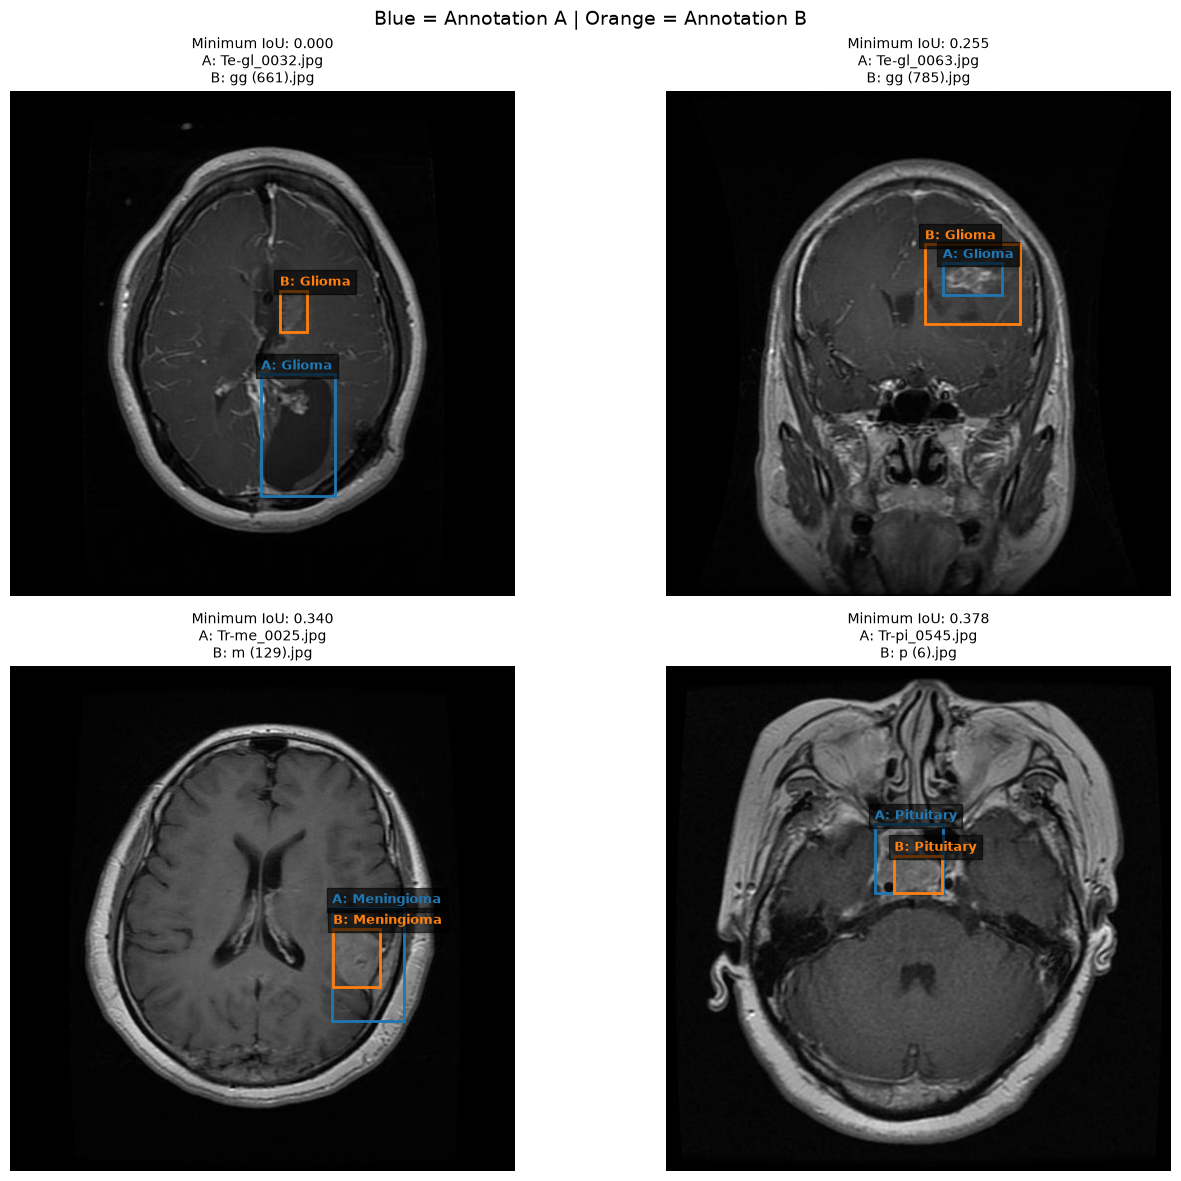

In [25]:
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle


low_groups = (
    df_iou[df_iou["agreement"] == "Low"]
    .sort_values("minimum_box_iou")
    .reset_index(drop=True)
)


def visualize_low_iou_groups(start=0, count=4):

    selected = low_groups.iloc[start:start + count]

    if selected.empty:
        print("No groups to display.")
        return

    ncols = 2
    nrows = (len(selected) + 1) // 2

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14, 6 * nrows),
    )

    axes = np.atleast_1d(axes).ravel()

    colors = ["tab:blue", "tab:orange"]

    for ax, (_, record) in zip(axes, selected.iterrows()):

        image_hash = record["hash"]

        versions = (
            df_duplicate_details[
                df_duplicate_details["hash"] == image_hash
            ]
            .reset_index(drop=True)
        )

        # Find the annotation-version pair with
        # the lowest individual matched-box IoU.
        worst_pair = None
        worst_score = float("inf")

        for i, j in combinations(range(len(versions)), 2):

            sig_a = versions.loc[i, "annotation_signature"]
            sig_b = versions.loc[j, "annotation_signature"]

            scores = match_boxes(sig_a, sig_b)

            if scores and min(scores) < worst_score:
                worst_score = min(scores)
                worst_pair = (i, j)

        if worst_pair is None:
            ax.axis("off")
            continue

        image_path = df_hashes.loc[
            df_hashes["hash"] == image_hash, "path"
        ].iloc[0]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        width, height = image.size

        ax.imshow(image)

        for version_index, row_index in enumerate(worst_pair):

            version = versions.loc[row_index]
            signature = version["annotation_signature"]

            for class_id, x, y, w, h in signature:

                x_min = (x - w / 2) * width
                y_min = (y - h / 2) * height

                rect = Rectangle(
                    (x_min, y_min),
                    w * width,
                    h * height,
                    fill=False,
                    edgecolor=colors[version_index],
                    linewidth=2,
                )

                ax.add_patch(rect)

                ax.text(
                    x_min,
                    max(y_min - 5, 0),
                    f"{'AB'[version_index]}: {CLASS_NAMES[class_id]}",
                    color=colors[version_index],
                    fontsize=9,
                    weight="bold",
                    bbox=dict(facecolor="black", alpha=0.6),
                )

        first = versions.loc[worst_pair[0], "filename"]
        second = versions.loc[worst_pair[1], "filename"]

        ax.set_title(
            f"Minimum IoU: {worst_score:.3f}\n"
            f"A: {first}\nB: {second}",
            fontsize=10,
        )

        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    fig.suptitle(
        "Blue = Annotation A | Orange = Annotation B",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()


visualize_low_iou_groups(start=0, count=4)


## 1.12 — Investigation of Structural Annotation Conflicts

### Objective

Investigate duplicate MRI images whose YOLO annotations contain different numbers of objects or different class identifiers.

### Previous Findings

Among 1,228 exact-duplicate image groups:

- 1,132 contain coordinate-only annotation differences.
- 88 contain different bounding-box counts.
- 5 contain the same number of boxes but different class multisets.
- 3 have identical annotation signatures.

The 88 groups with different box counts and the 5 groups with class differences form the 93 structurally inconsistent groups.

### Why Is This Important?

Different numbers of boxes may indicate missing or additional annotations.

Different class IDs may indicate class-label inconsistencies or annotations of different structures.

These issues must be investigated before selecting a canonical annotation for each duplicated image.

### Methodology

1. Separate object-count disagreements from class-label disagreements.
2. Inspect representative annotation versions.
3. Visualize their bounding boxes.
4. Determine which cases require manual review.

The original dataset will remain unchanged.


In [26]:
# Step 1: Identify all structural conflicts

structural_conflicts = df_comparison[
    df_comparison["different_class_multisets"]
].copy()

# Step 2: Separate the conflict categories

count_conflicts = structural_conflicts[
    structural_conflicts["different_box_counts"]
]

class_conflicts = structural_conflicts[
    ~structural_conflicts["different_box_counts"]
]

# Step 3: Display the results

print("Total structural conflicts:", len(structural_conflicts))

print("Different box counts:", len(count_conflicts))

print("Same box count, different classes:", len(class_conflicts))

# Step 4: Examine annotation versions

def inspect_conflict(image_hash):

    group = df_duplicate_details[
        df_duplicate_details["hash"] == image_hash
    ]

    for _, row in group.iterrows():

        signature = row["annotation_signature"]

        print("\nImage:", row["filename"])
        print("Split:", row["split"])
        print("Number of boxes:", len(signature))
        print("Class IDs:", [box[0] for box in signature])
        print("Annotations:", signature)


print("\n--- Example: Different Box Counts ---")

inspect_conflict(count_conflicts.iloc[0]["hash"])

print("\n--- Example: Different Classes ---")

inspect_conflict(class_conflicts.iloc[0]["hash"])

Total structural conflicts: 93
Different box counts: 88
Same box count, different classes: 5

--- Example: Different Box Counts ---

Image: Tr-pi_0751.jpg
Split: Train
Number of boxes: 1
Class IDs: [3]
Annotations: ((3, 0.50684, 0.60059, 0.15039, 0.15039),)

Image: p (91).jpg
Split: Train
Number of boxes: 2
Class IDs: [3, 3]
Annotations: ((3, 0.49414, 0.70508, 0.07422, 0.05469), (3, 0.51758, 0.60254, 0.14453, 0.15039))

--- Example: Different Classes ---

Image: Te-gl_0043.jpg
Split: Train
Number of boxes: 1
Class IDs: [1]
Annotations: ((1, 0.53418, 0.30957, 0.07227, 0.0957),)

Image: gg (705).jpg
Split: Train
Number of boxes: 1
Class IDs: [0]
Annotations: ((0, 0.5332, 0.31445, 0.07031, 0.08594),)


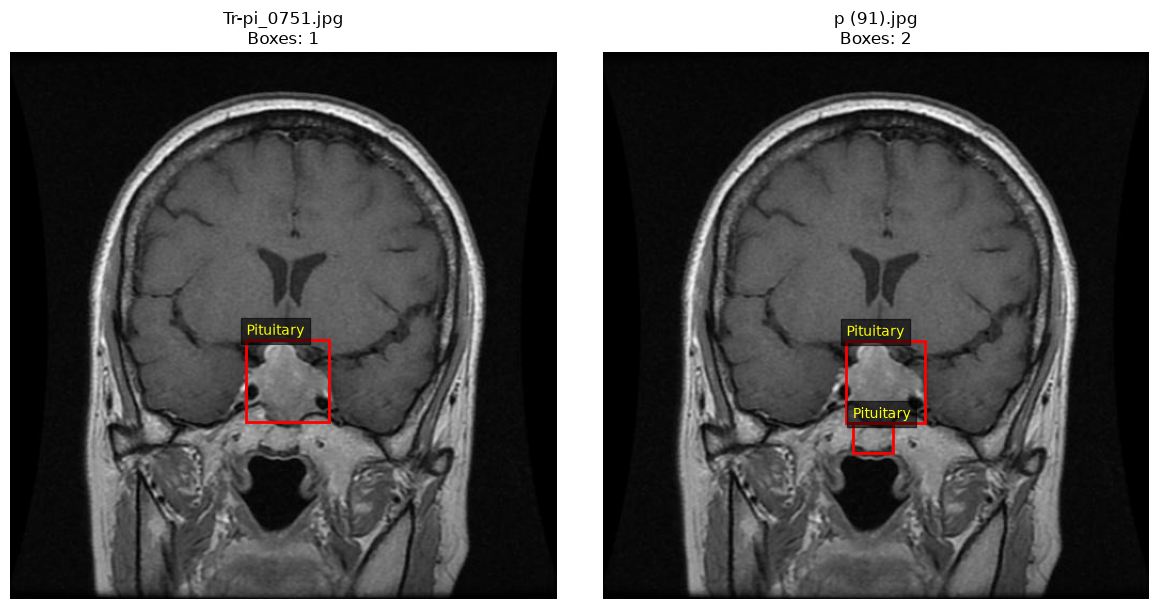

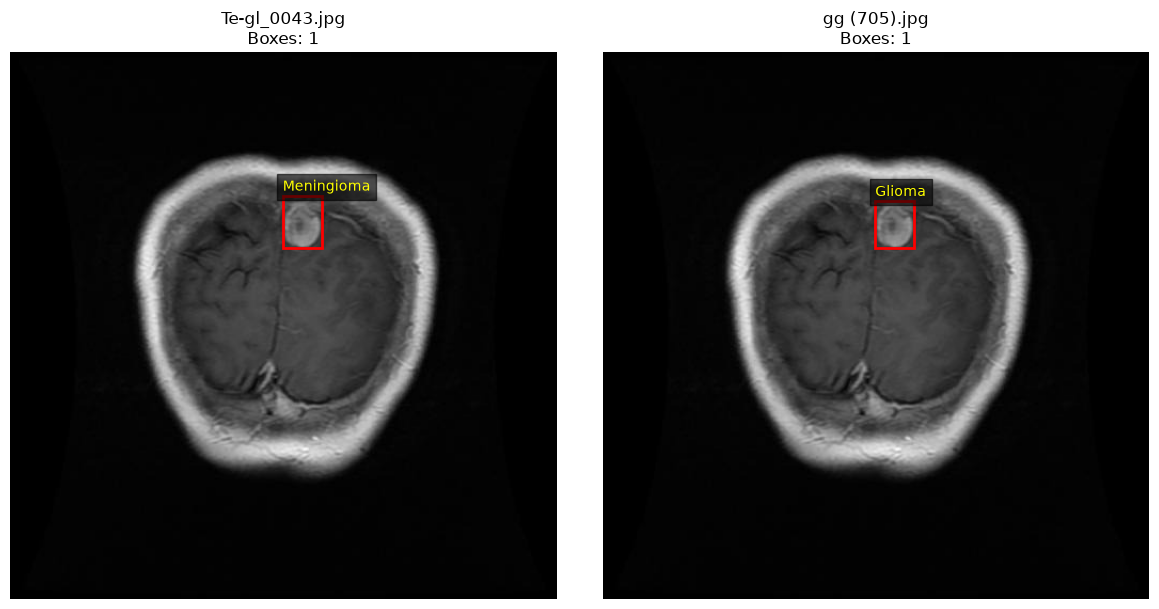

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from itertools import combinations


def visualize_conflict(image_hash):

    versions = df_duplicate_details[
        df_duplicate_details["hash"] == image_hash
    ].reset_index(drop=True)

    # Find two versions with different class multisets
    selected_pair = None

    for i, j in combinations(range(len(versions)), 2):

        sig_a = versions.loc[i, "annotation_signature"]
        sig_b = versions.loc[j, "annotation_signature"]

        classes_a = sorted(box[0] for box in sig_a)
        classes_b = sorted(box[0] for box in sig_b)

        if classes_a != classes_b:
            selected_pair = (i, j)
            break

    if selected_pair is None:
        print("No structural disagreement found.")
        return

    image_path = df_hashes.loc[
        df_hashes["hash"] == image_hash,
        "path"
    ].iloc[0]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    width, height = image.size

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    for ax, index in zip(axes, selected_pair):

        version = versions.loc[index]
        signature = version["annotation_signature"]

        ax.imshow(image)

        for class_id, x, y, w, h in signature:

            x_min = (x - w / 2) * width
            y_min = (y - h / 2) * height

            rect = Rectangle(
                (x_min, y_min),
                w * width,
                h * height,
                fill=False,
                edgecolor="red",
                linewidth=2
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                max(y_min - 5, 0),
                CLASS_NAMES[class_id],
                color="yellow",
                fontsize=10,
                bbox=dict(facecolor="black", alpha=0.6)
            )

        ax.set_title(
            f"{version['filename']}\n"
            f"Boxes: {len(signature)}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Example 1: Different number of boxes
visualize_conflict(count_conflicts.iloc[0]["hash"])

# Example 2: Same number of boxes, different classes
visualize_conflict(class_conflicts.iloc[0]["hash"])


### 1.12.1 — Structural Annotation Conflict Findings

#### 1. Summary

A total of **93 duplicate image groups** contain structural annotation disagreements.

| Conflict Type | Groups |
|---|---:|
| Different bounding-box counts | 88 |
| Same box count, different class multisets | 5 |
| **Total** | **93** |

These results confirm that some byte-identical MRI images have different object detection annotations.

---

#### 2. Bounding-Box Count Disagreement

The following duplicate images were inspected:

- `Tr-pi_0751.jpg`
- `p (91).jpg`

Both images are located in the training partition of the Pituitary class.

**Annotation A:**

- Number of boxes: 1
- Class IDs: [3]

**Annotation B:**

- Number of boxes: 2
- Class IDs: [3, 3]

The first annotation contains one bounding box, while the second contains two.

Visual inspection shows that the larger boxes identify similar regions.

However, Annotation B includes an additional small box directly below the larger box.

**Interpretation:**

The discrepancy concerns object count rather than class identity.

The additional box might represent another annotated region, a subdivision of an existing region, or an annotation error.

We cannot conclude that it represents an additional tumor without further validation.

Automatically merging both annotation versions could introduce incorrect training targets.

---

#### 3. Class Identifier Disagreement

The following duplicate image was inspected:

`Te-gl_0043.jpg`

The two annotation versions contain one bounding box each.

**Annotation A:**

`1 0.53418 0.30957 0.07227 0.09570`

**Annotation B:**

`0 0.53320 0.31445 0.07031 0.08594`

Under the provisional class mapping:

- Class 0: Glioma
- Class 1: Meningioma

The coordinates are geometrically similar, with an approximate IoU of 0.87.

However, the annotations assign different classes to nearly the same region.

**Interpretation:**

This is a semantic labeling disagreement.

High geometric overlap does not resolve conflicting class identities.

The image belongs to the Glioma folder, but the image-level folder label is not sufficient evidence to establish which bounding-box class is correct.

This case requires further review.

---

#### 4. Implications for Dataset Cleaning

The results show why duplicate removal and annotation cleaning must be treated as related but distinct operations.

For classification, the priority is selecting unique images with reliable image-level labels.

For detection, the preprocessing pipeline must also preserve reliable bounding-box coordinates and class identifiers.

The proposed strategy is:

1. Preserve the original dataset.
2. Group byte-identical images.
3. Investigate structural annotation conflicts.
4. Identify uncertain annotations requiring review.
5. Select canonical annotations only when justified.
6. Exclude unresolved cases from the trusted detection subset when necessary.
7. Document all cleaning decisions.

---

### Overall Conclusion

The structural conflict analysis identified two important examples.

The first involves different numbers of Pituitary bounding boxes on identical images.

The second involves nearly identical bounding-box locations assigned to different tumor classes.

These findings demonstrate that geometric agreement and semantic agreement must be evaluated separately.

No annotation corrections have been applied.

### Next Step

Investigate all five duplicate groups with equal box counts but different class identifiers.

Afterward, review representative cases from the 88 groups with different bounding-box counts and establish reproducible data-cleaning rules.


Class-conflict groups: 5

CONFLICT GROUP 1

Image: Te-gl_0043.jpg
Split: Train
Number of boxes: 1
Class IDs: [1]
Annotations: ((1, 0.53418, 0.30957, 0.07227, 0.0957),)

Image: gg (705).jpg
Split: Train
Number of boxes: 1
Class IDs: [0]
Annotations: ((0, 0.5332, 0.31445, 0.07031, 0.08594),)


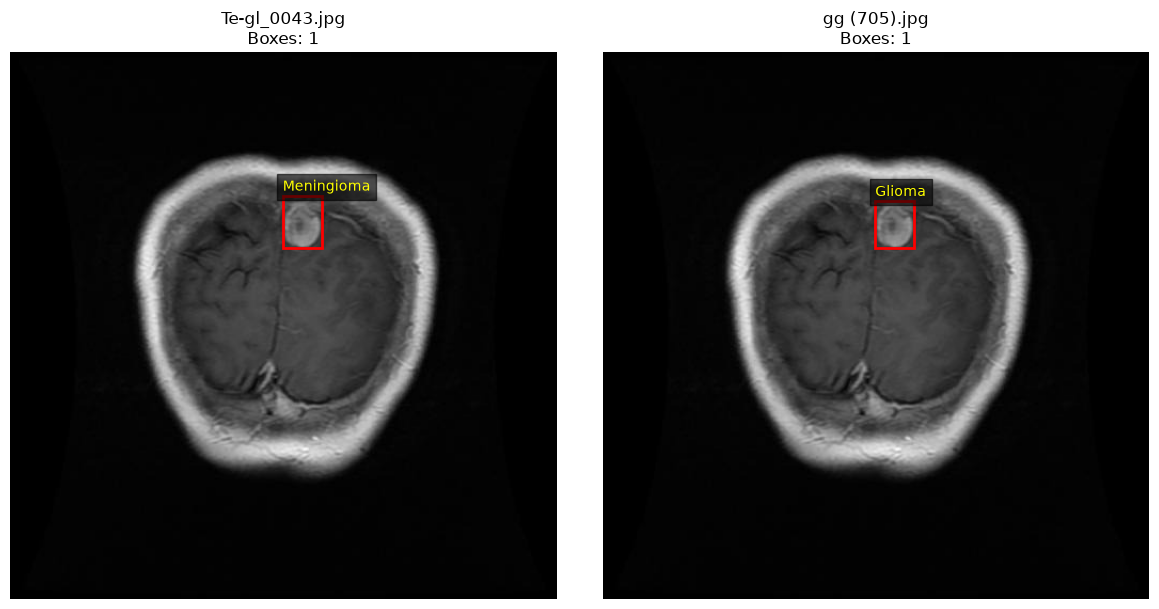


CONFLICT GROUP 2

Image: Tr-me_0023.jpg
Split: Train
Number of boxes: 1
Class IDs: [0]
Annotations: ((0, 0.44922, 0.44531, 0.16406, 0.21484),)

Image: m (127).jpg
Split: Train
Number of boxes: 1
Class IDs: [1]
Annotations: ((1, 0.44922, 0.43262, 0.16797, 0.13867),)


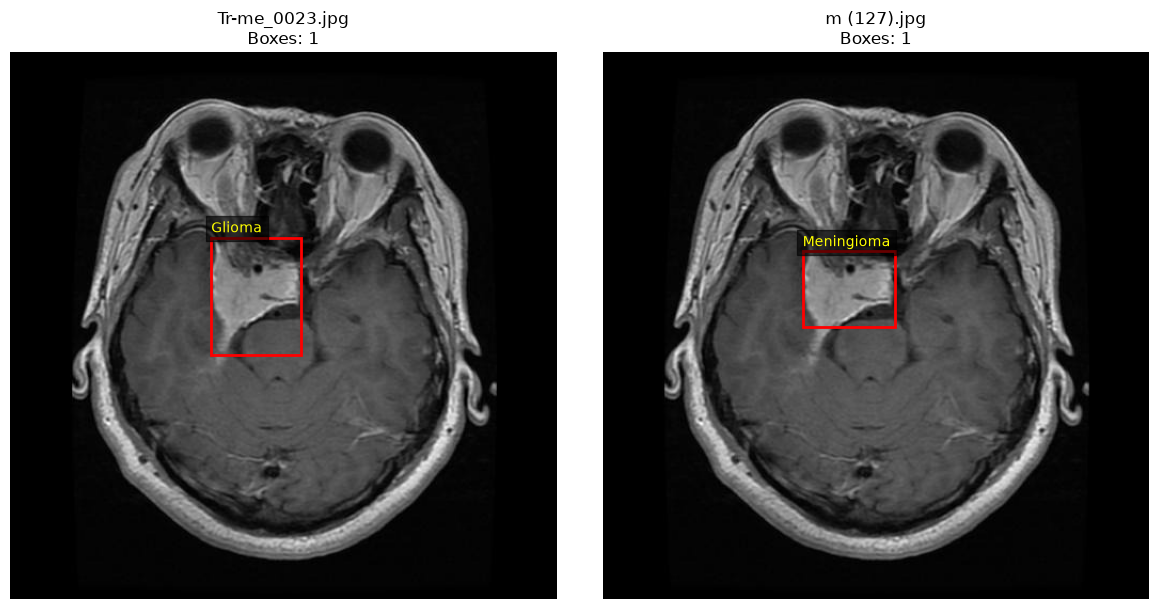


CONFLICT GROUP 3

Image: Tr-me_0385.jpg
Split: Train
Number of boxes: 1
Class IDs: [0]
Annotations: ((0, 0.31738, 0.33887, 0.18164, 0.24023),)

Image: m2 (114).jpg
Split: Train
Number of boxes: 1
Class IDs: [1]
Annotations: ((1, 0.32227, 0.33398, 0.16797, 0.23047),)


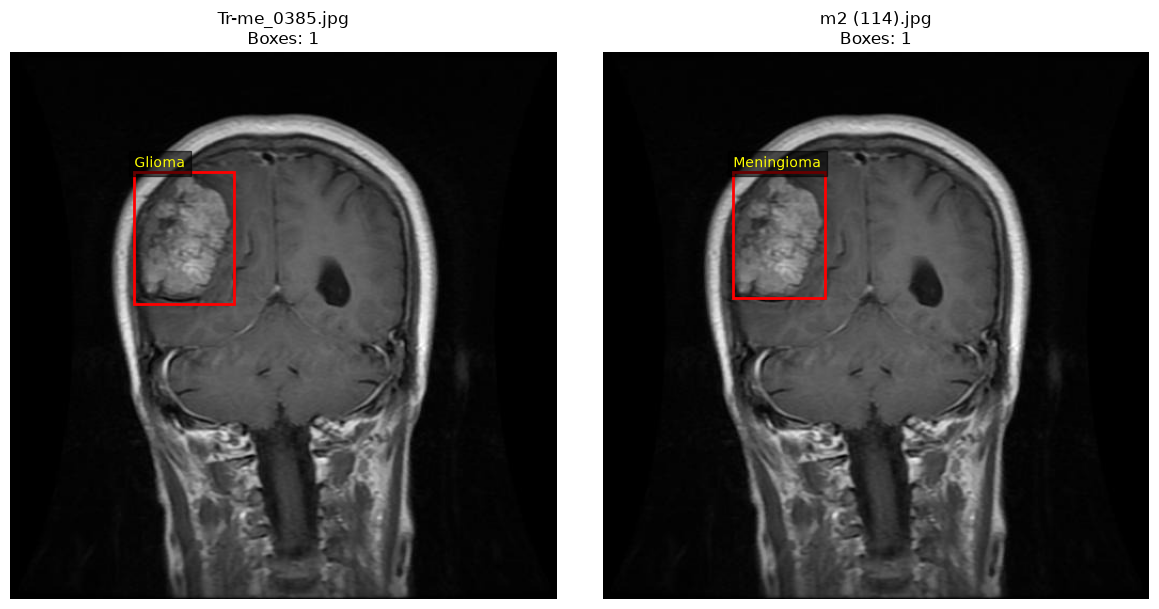


CONFLICT GROUP 4

Image: Tr-gl_0111.jpg
Split: Train
Number of boxes: 2
Class IDs: [0, 0]
Annotations: ((0, 0.34863, 0.38867, 0.10742, 0.09766), (0, 0.37598, 0.48828, 0.0957, 0.12109))

Image: gg (778).jpg
Split: Train
Number of boxes: 2
Class IDs: [0, 3]
Annotations: ((0, 0.3623, 0.45215, 0.13867, 0.20117), (3, 0.52246, 0.56055, 0.07227, 0.09766))


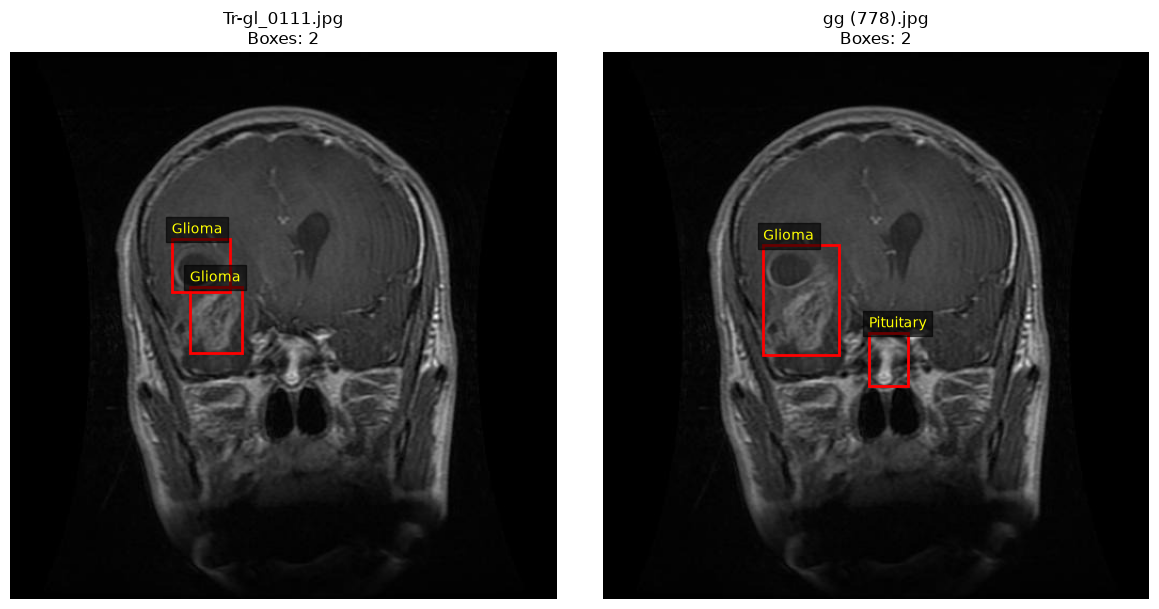


CONFLICT GROUP 5

Image: Tr-me_0569.jpg
Split: Train
Number of boxes: 1
Class IDs: [1]
Annotations: ((1, 0.68066, 0.25, 0.18164, 0.16797),)

Image: m3 (120).jpg
Split: Train
Number of boxes: 1
Class IDs: [3]
Annotations: ((3, 0.68848, 0.25195, 0.16211, 0.16406),)


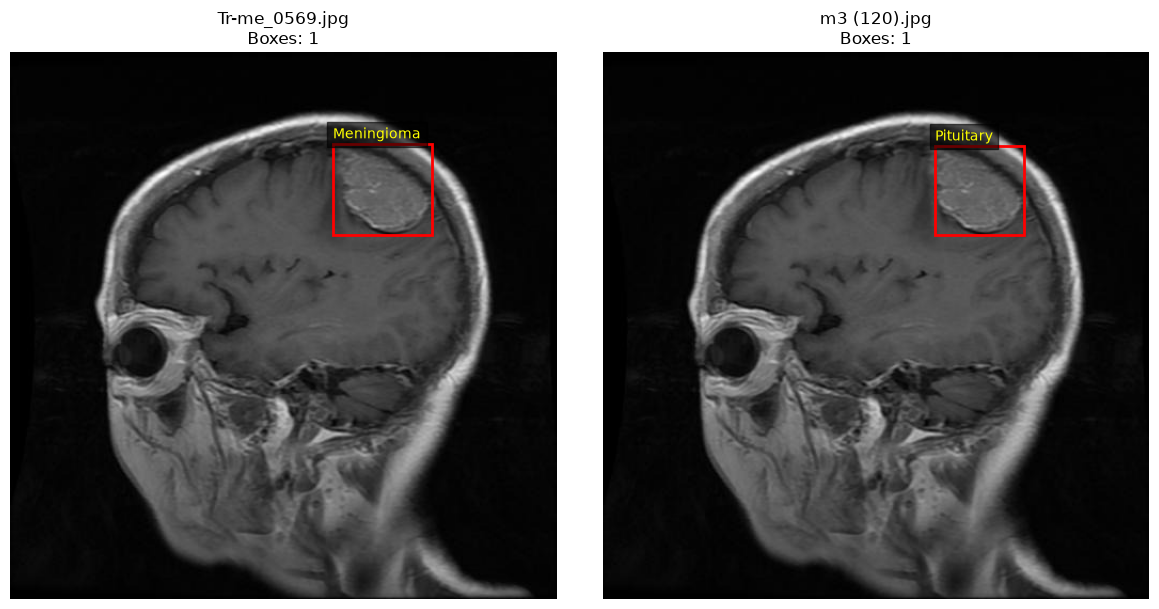

In [29]:
print("Class-conflict groups:", len(class_conflicts))

for i, image_hash in enumerate(class_conflicts["hash"], start=1):

    print(f"\n{'=' * 50}")
    print(f"CONFLICT GROUP {i}")
    print(f"{'=' * 50}")

    inspect_conflict(image_hash)

    visualize_conflict(image_hash)